# Author: Lena Noack
# GNU General Public License v3.0 (GPL-3.0)
#Interior Structure Model


# For the solar system, since there is more certainty of data, the work made some changes to the initial ROWs code. This is because it is initially as generic as possible, given that the goal is to apply it to exoplanets where most of the data is unknown. However, the application to the solar system can be better evaluated, considering that more data is available. For this reason, the following parameters were also included as input:

- xelem
- DTcmb: O único que teve seu valor alterado foi Venus, para se adequar a referencia: O’ROURKE, Joseph G.; KORENAGA, Jun. Thermal evolution of Venus with argon degassing. Icarus, v. 260, p. 128-140, 2015.

# Furthermore, the determination of the core, that is, the get_Tmelt_core function, has been adjusted to work better with exoplanets (or satellites) with very low mass and radius. This adjustment is necessary because for satellites and Earth-like exoplanets, the pressures and temperatures present in the core are of very different orders of magnitude, and the standard get_Tmelt_core of the ROW model does not make this distinction. Also, the get_Tmelt_core of the ROW model does not consider that the presence of S impacts the core (because it is a simplification, so that it can be applied to exoplanets that have these unknown values).

In [1]:
import numpy as np
import math
import csv
import pandas as pd
import matplotlib.pyplot as plt
import os

In [2]:
from EOS_functions import EOS_rock, EOS_core, EOS_core_mixed
from values import *
from Help_functions import get_Tmelt_MO, get_Tmelt_water, getphase
from water import getWater


In [3]:
def temp_pla2(T_e, R_e, a):
    t_p=T_e*(R_e/(2*a))**(1/2)
    return t_p

# Unidades: 1, kg, kg, km, km, adimensional 
def pressao(P_t, M_p, M_t, R_p, R_t, tipo): 
    if tipo == 1: #mercury
        beta = 1.05*10**(-13)
    elif tipo == 0:#venus
        beta = 108.27
    elif tipo == 2:#mars
        beta = 0.0467
    elif tipo==3 or tipo==4 : #earth
        beta = 1.014
    else:# Any other type, I'll disregard those anyway.
        beta=1
    P=beta*((M_p/M_t)**2)*((R_t/R_p)**4)*P_t
    return P*101325

In [4]:
def get_Tmelt_core(P_Pa, xS=0.0, xSi=0.0, xO=0.0):
    P_GPa = P_Pa * 1e-9
    P_safe = max(P_GPa, 0.5) # Floor to ensure that P_gpa n is zero or very close to zero in the case of satellites
    # Anzellini et al. (2013), Science and Stixrude et al., 2014
    T_b = 1811 + 65*P_GPa + 1.2*P_GPa**2 
    T_a = 6230*(P_safe/241)**0.515
    # Stixrude et al., 2014
    T_s = 6500*(P_safe/340)**0.515

    w1 = 1/(1+np.exp(-(P_GPa-8)/3)) # low pressures
    w2 = 1/(1+np.exp(-(P_GPa-150)/30)) # high pressures
    # w1 and w2 are sigmoidal weight functions to make a smooth transition between pressure regimes.
    # These weights are important because this get_Tmelt_core function will work in different pressure regimes, ranging from Earth to Callisto, for example.
    
    T_melt_Fe = (1-w2)*((1-w1)*T_b + w1*T_a) + w2*T_s

    if xS > 0:
        #Melting point depressions due to sulfur are parameterized by Gaussian functions considering pressure ranges.
        # Pressure ranges are necessary to accommodate scenarios ranging from Earth to satellites such as Io, Europa, the Moon, etc.
        
        #Usselman, T.M. (1975). Experimental approach to the state of the core: Part I. The liquidus relations of the Fe-rich portion of the Fe–Ni–S system from 30 to 100 kb. American Journal of Science, 275, 278–290.
        boost_low  = 300  * np.exp(-P_GPa/8)
        # CHUDINOVSKIKH, Liudmila; BOEHLER, Reinhard. Eutectic melting in the system Fe–S to 44 GPa. Earth and Planetary Science Letters, v. 257, n. 1-2, p. 97-103, 2007.
        boost_mid  = 1800 * np.exp(-((P_GPa-40)/40)**2)
        
        dS = xS*(boost_low + boost_mid) 
    else:
        dS = 0
    T_melt_core = T_melt_Fe - dS
    return T_melt_core


In [5]:
def interior_structure(M,x_Fe_tot,x_H2O_tot, t, P, xelem, DTcmb = -1.0):
  '''
  input:
   M: Mass in Earth masses
   x_Fe_tot: Iron weigth fraction in percent of the entire planet (core + mantle)
   x_H2O_tot: Water weigth fraction in percent of surface water/ice layer
  return:
   Rp_E - planet radius in Earth radii
   MOI - moment of inertia factor
   radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu - profiles of different planetary properties
   mat - material layers (<0 ices, 0 water, >0 different rock and core layers)
  '''

  '''Set initialization parameters'''
  Dcr = 50e3      # thickness of crustal layer in m
  Dlid = 300e3    # thickness of lithosphere, only used to set upper mantle temperature
  Psurf = P     # atmospheric surface pressure
  Tsurf = t     # potential surface temperature in K
  Tlid = 0.0    #2000 # in K; if set to 0, then mantle melt temp is used at Dlid depth to set Tlid
  nr = 500         # radial resolution from center of planet to surface
  tol = 0.001     # Convergence parameter
  maxIter = 20   # max number iterations

  # light elements in the core -> array added for molar fractions Si,C,S,O; e.g. (0.2 S -> Fe0.8S0.2), means weight fraction of 12 wt-% S
  xelem = xelem # initial core-averaged value. Modified to vary according to the values for the planets in the solar system.
  xelem_ic = np.array([0.00,0.00,0.07,0.00]) # fixed inner core value (no real partitioning included yet; outer core value calculated during inner core growth

  X_FeM_mol = 0.1 # iron number in mantle (ratio of Fe-bearing molecules divided by Mg- and Fe-bearing molecules)
  X_H2OM = 0      # water content in mantle in wt-%, only used for el cond profile versions 2-4
  ec_model = 1    # electrical conductivity profiles: 1 - Xu, 2 - mat-dep prof without Fe, 3 - as 2 but with Fe dependence, 4 - as 3 but newer parameters


  '''Distribute iron between core and mantle'''

  x_Fe_tot = x_Fe_tot/100 # weight fraction instead of percent
  x_H2O_tot = x_H2O_tot/100
  M = M * 5.972*10**24 # mass in kg
  Mw = M*x_H2O_tot 
  G = 6.67384*10**(-11) # gravitational constant in m^3 / (kg s^2)

  # Molar masses:
  mMg=24.305; mFe=55.845; mSi=28.0855; mO=15.9994

  XmFe = 2*X_FeM_mol*mFe/(X_FeM_mol*2*(mFe-mMg) + 2*mMg+mSi+4*mO) # mantle mass fraction of iron w.r.t. mantle mass

  
  x_Fe = ( x_Fe_tot*M - XmFe*(M-Mw) ) / (M*(1-XmFe)) # core mass fraction w.r.t. total planet mass
  Mc = x_Fe*M
  if Mc<0.0:
      raise ValueError(f"Not enough iron in planet to have {iron_number} as iron number")
      Mc = 0.0
      x_Fe = 0.0
      XmFe = x_Fe_tot*M / (M-Mw) # adapt XmFe such that all iron is in mantle

      #XmFe * (X_FeM_mol*2*(mFe-mMg) + 2*mMg+mSi+4*mO) = 2*X_FeM_mol*mFe
      X_FeM_mol = XmFe*(2*mMg+mSi+4*mO)/(2*mFe-2*(mFe-mMg)*XmFe) # adapt mantle iron number

  Mm = M - Mc - Mw

  '''Initialization routines'''

  rho_c = 11000 # guess for core density in kg/m^3
  rho_m = 4000 # guess for mantle density in kg/m^3
  rho_w = 1000 # guess for water density in kg/m^3
  cp_c = 800 # guess for core heat capacity in J/kg K
  cp_m = 1300 # guess for mantle heat capacity in J/kg K
  cp_w = 4200 # guess for water heat capacity in J/kg K
  alpha_c = 0.00001 # guess for core thermal expansion ceoff. in 1/K
  alpha_m = 0.000025 # guess for mantle thermal expansion ceoff. in 1/K
  alpha_w = 0.00007 # guess for water thermal expansion ceoff. in 1/K

  Rc = ( Mc*3.0 / (4.0*math.pi*rho_c) )**(1/3) # first guess core radius
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius
  Rp = ( Mw*3.0 / (4.0*math.pi*rho_w) + Rm**3 )**(1/3) # first guess planet radius

  # Define arrays
  dr = np.zeros(nr) # distance between radius points
  radius = np.zeros(nr) # vector of radii, first radius is dr
  pressure = np.zeros(nr)
  gravity = np.zeros(nr)
  temperature = np.zeros(nr)
  density = np.zeros(nr)
  alpha = np.zeros(nr)
  cp = np.zeros(nr)
  KT = np.zeros(nr)
  KS = np.zeros(nr)
  mu = np.zeros(nr)
  mass = np.zeros(nr)
  mat = np.zeros(nr)
  elcond = np.zeros(nr)

  # set number of grid points in the three layers (core/mantle/water) based on initial radii, to be kept constant throughout iteration
  nc = int(nr * Rc/Rp)
  if (x_H2O_tot==0):
    nm = nr - nc
    nw = 0
  else:
    nm = int(nr * Rm/Rp) - nc
    nw = nr - nm - nc

  # Initialization of arrays: surface values
  if Mw>0:
    density[nr-1] = rho_w
    alpha[nr-1] = alpha_w
    cp[nr-1] = cp_w
  elif Mm>0:
    density[nr-1] = rho_m
    alpha[nr-1] = alpha_m
    cp[nr-1] = cp_m
  else: # pure iron shell
    density[nr-1] = rho_c
    alpha[nr-1] = alpha_c
    cp[nr-1] = cp_c
    Rc = Rp

  # Initialization of arrays: interpolation over depth
  for i in range(0,nr):
    if i==0:
      r_prev = 0.0
    else:
      r_prev = radius[i-1]
    if i<nc:
      dr[i] = Rc/float(nc)
      density[i] = rho_c
      alpha[i] = alpha_c
      cp[i] = cp_c
    elif i<nc+nm:
      dr[i] = (Rm-Rc)/float(nm)
      density[i] = rho_m
      alpha[i] = alpha_m
      cp[i] = cp_m
    else:
      dr[i] = (Rp-Rm)/float(nw)
      density[i] = rho_w
      alpha[i] = alpha_w
      cp[i] = cp_w
    radius[i] = r_prev + dr[i]


  # pressure and temperature are interpolated from surface downwards
  # gravity has boundary condition 0 in center (and not at surface)
  pressure[nr-1] = Psurf # 1 bar surface pressure
  temperature[nr-1] = Tsurf # surface temperature
  gravity[nr-1] = G*M/Rp**2 # first guess surface gravity
  plid = Dlid*rho_m*gravity[nr-1] # first guess at plid, will be calculated below


  '''Start iteration to determine interior structure'''

  iter = 1
  Store_V_vec_old = []
  Rp_old = 0
  while (abs(Rp-Rp_old) > tol) and (iter < maxIter):
      # store old Rp value to determine convergence
      Rp_old = Rp

      # average values will be re-determined from material properties
      rho_c = 0; rho_m = 0; rho_w = 0; vol_c = 0; vol_m = 0; vol_w = 0

      # update vectors for radius, gravity, pressure and temperature
      for i in range(0,nr):
        if i==0:
          r_prev = 0.0
        else:
          r_prev = radius[i-1]
        if i<nc:
          dr[i] = Rc/float(nc)
        elif i<nc+nm:
          dr[i] = (Rm-Rc)/float(nm)
        else:
          dr[i] = (Rp-Rm)/float(nw)
        radius[i] = r_prev + dr[i]

      
      gravity[0] = radius[0] * 4/3*math.pi*G*density[0]
      for i in range(1,nr):
          gravity[i] = gravity[i-1] + dr[i-1] * (4*math.pi*G*density[i-1] - 2*gravity[i-1]/radius[i-1])

      for i in range(nr-2,-1,-1):
          pressure[i] = pressure[i+1] + dr[i]*gravity[i]*density[i]
          if i>=nc+nm: # ocean layer, we assume here adiabatic profile from the surface
              temperature[i] = temperature[i+1] + dr[i]*alpha[i+1]/cp[i+1] * gravity[i+1]*temperature[i+1]
          elif Rm-radius[i]<Dlid: # in lithosphere
              if Mw>0:
                Ts = temperature[nc+nm]
              else:
                Ts = Tsurf
              if Tlid>0:
                  
                  temperature[i] = Ts + (Tlid-Ts)*(radius[nc+nm-1]-radius[i])/Dlid
              else:
                  temperature[i] = Ts + (get_Tmelt_MO(plid)-Ts)*(radius[nc+nm-1]-radius[i])/Dlid
          elif Rm-radius[i+1]<Dlid: # first grid point in mantle
              if Tlid>0:
                  temperature[i] = Tlid 
              else:
                  temperature[i] = get_Tmelt_MO(plid) 
              plid = pressure[i] 
          elif (i+1==nc):
              temperature[i] = temperature[i+1] + dr[i]*alpha[i+1]/cp[i+1] * gravity[i+1]*temperature[i+1]
              if DTcmb >= 0:
                  
                  temperature[i] = temperature[i] + DTcmb
              else:
                  
                  temperature[i] = temperature[i] + (get_Tmelt_MO(pressure[i])-temperature[i]) * abs(DTcmb)
          else: 
              temperature[i] = temperature[i+1] + dr[i]*alpha[i+1]/cp[i+1] * gravity[i+1]*temperature[i+1]
          
      Store_V_vec = []
      ric = 0
      for i in range(nr): # from center to surface
          # get correct layer depending on core size, mantle phase transitions, and crust thickness
          # 7 layers in total: 6-core, 5-ppv, 4-pv, 3-ri, 2-wa, 1-ol, 0-cr
          if i < nc:
              # iron core
              if temperature[i] < get_Tmelt_core(pressure[i], xS=xelem[2], xSi=xelem[0], xO=xelem[3]):
                mat[i] = 8 # inner core
                ric = radius[i] # updated until outer core is reached
              else:
                mat[i] = 7 # outer core
              arr_species = ['fehcp']
              mole_vec = [1]
          elif i >= nc+nm:
              # water layer
              mat[i] = 0 # liquid water or water ice, phase defined below
              arr_species = ['h2o']
              [Tm,phase] = get_Tmelt_water(pressure[i])
              if temperature[i]<Tm:
                mat[i] = -phase # ice phases stored with negative values
              mole_vec = [1]
          elif pressure[i] >= (127 + 0.006*(temperature[i]-2840))*10**9:
              # post-perovskite
              mat[i] = 6
              arr_species = ['mppv', 'fppv','pe','wu']
              mole_vec = [0.5*(1-X_FeM_mol),0.5*(X_FeM_mol),0.5*(1-X_FeM_mol),0.5*(X_FeM_mol)]
          elif pressure[i] >= (22.9 - 0.0025*(temperature[i]-2260))*10**9:
              # perovskite
              mat[i] = 5
              arr_species = ['mgpv', 'fepv','pe','wu']
              mole_vec = [0.5*(1-X_FeM_mol),0.5*(X_FeM_mol),0.5*(1-X_FeM_mol),0.5*(X_FeM_mol)]
          elif (pressure[i] >= (6.2 + 16.7*(1-X_FeM_mol) + 0.005*(temperature[i]-2260))*10**9) & (radius[i] <= Rm-Dcr):
              # ringwoodite
              mat[i] = 4
              arr_species = ['mgri', 'feri']
              mole_vec = [1-X_FeM_mol,X_FeM_mol]
          elif (pressure[i] >= (4.92 + 5.4*(1-X_FeM_mol) + 0.0025*temperature[i])*10**9) & (radius[i] <= Rm-Dcr):
              # wadsleyite
              mat[i] = 3
              arr_species = ['mgwa', 'fewa']
              mole_vec = [1-X_FeM_mol,X_FeM_mol]
          elif radius[i] <= Rm-Dcr:
              # olivine
              mat[i] = 2
              arr_species = ['fo', 'fa']
              mole_vec = [1-X_FeM_mol,X_FeM_mol]
          else:
              # crust
              mat[i] = 1
              arr_species = ['an','di','qtz'] #Anorthite Feldspar Ca[Al2Si2]O8; Diopside CaMgSi2O6; Quartz SiO2
              mole_vec = [0.5, 0.25, 0.25]

          # mole fraction to mass fraction
          molmass = np.zeros(len(mole_vec))
          for k,species in enumerate(arr_species):
              res = values(species) # params for species
              molmass[k] = res.M
          mf_vec = mole_vec*molmass / np.sum(mole_vec*molmass)


         
          if mat[i] >= 7:
              if mat[i] == 8:
                xelemc = xelem_ic
              else:
                xelemc = (xelem * radius[nc-1]**3 - xelem_ic*ric**3)/(radius[nc-1]**3-ric**3) 
              
              cp[i],density[i],alpha[i],KT[i],KS[i],mu[i],V_vec = EOS_core_mixed(pressure[i]/10**9,temperature[i],xC=xelemc[1], xSi=xelemc[0], xS=xelemc[2], xO=xelemc[3])

          else:
              if Store_V_vec_old == []:
                  cp[i],density[i],alpha[i],KT[i],KS[i],mu[i],V_vec = EOS_rock(pressure[i]/10**9,temperature[i],arr_species,mf_vec)
              else:
                 
                  cp[i],density[i],alpha[i],KT[i],KS[i],mu[i],V_vec = EOS_rock(pressure[i]/10**9,temperature[i],arr_species,mf_vec,Store_V_vec_old[i])
          Store_V_vec.append(V_vec)

          # check profiles
          # update mass vector (used here only for visualization)
          if i==0:
              mass[i] = 4*math.pi*radius[i]**3*density[i]
          else:
              mass[i] = mass[i-1] + (radius[i]-radius[i-1])*4*math.pi*radius[i]**2*density[i]

          #Get new average densities for radius update
          if i==0:
              vol = 4/3 * math.pi * radius[i]**3
          else:
              vol = 4/3 * math.pi * (radius[i]**3 - radius[i-1]**3)

          if i <= nc:
              rho_c = rho_c + density[i]*vol
              vol_c = vol_c + vol
          elif i <= nc+nm:
              rho_m = rho_m + density[i]*vol
              vol_m = vol_m + vol
          else:
              rho_w = rho_w + density[i]*vol
              vol_w = vol_w + vol

      # Error with surface density for iron incl. light species
      if density[nr-1] < 0:
          density[nr-1] = density[nr-2]

      Store_V_vec_old = Store_V_vec

      if vol_c==0:
          vol_c=1 # in case that no core exists
      if vol_m==0:
          vol_m=1 # in case that no mantle exists
      if vol_w==0:
          vol_w=1 # in case that no water layer exists

      rho_c = rho_c / vol_c
      rho_m = rho_m / vol_m
      rho_w = rho_w / vol_w

      # update radius for core and mantle
      if Mc==0:
        Rc = 0
      else:
        Rc = (3*Mc/(4*math.pi*rho_c))**(1/3)
      if Mm==0:
        Rm = Rc
      else:
        if (rho_m>0.0):
          Rm = (Rc**3 + 3*Mm/(4*math.pi*rho_m))**(1/3)
        else:
          Rm = Rc
      if Mw==0:
        Rp = Rm
      else:
        if (rho_w>0.0): # can happen if surface water layer is smaller than resolution between two uppermost grid points
          Rp = (Rm**3 + 3*Mw/(4*math.pi*rho_w))**(1/3)
        else:
          Rp = Rm

      #print('{0:2d} {1:8.2f} {2:8.2f} {3:7.1f} {4:7.1f}'.format(iter,Rp/1000,Rc/1000,rho_m,rho_c))

      iter=iter+1


  '''Post-processing'''

  # Additional properties computed from final iteration (i.e. without influence on interior structure)

  # seismic velocity profiles
  vP = np.sqrt((KS*10**9+4/3*mu*10**9)/density)*10**-3 # in km/s
  vS = np.sqrt(mu*10**9/density)*10**-3 # in km/s

  # electrical conductivity
  kB = 8.61733e-5
  for i in range(nr):
      T = temperature[i]

      if mat[i]<=0:
          elcond[i] = 1.0e-20
      elif mat[i]<=2: # olivine layer and crust
          if ec_model==1:
              # Xu dry profile
              elcond[i] = 10.0**2.69*math.exp(-1.62/(kB*T))
          elif ec_model==2:
              # electrical conductivity in upper mantle following Yoshino and Katsura 2013
              elcond[i] = 10.0**4.73*math.exp(-2.31/(kB*T)) \
              + 10.0**1.9*X_H2OM*math.exp(-(0.92-0.16*X_H2OM**(1.0/3.0))/(kB*T))
          else:
              # electrical conductivity in upper mantle following Yoshino and Katsura 2013 with iron
              elcond[i] = 10.0**4.73*math.exp(-2.31/(kB*T)) \
              + 10.0**2.98*X_FeM_mol*math.exp(-(1.71-2.0*X_FeM_mol**(1.0/3.0))/(kB*T)) \
              + 10.0**1.9*X_H2OM*math.exp(-(0.92-0.16*X_H2OM**(1.0/3.0))/(kB*T))
      elif (mat[i]==3): # wadsleyite layer
          if ec_model==1:
              # Xu dry profile
              elcond[i] = 10.0**3.29*math.exp(-1.29/(kB*T))
          elif ec_model==2:
              # electrical conductivity in upper mantle following Yoshino 2008
              elcond[i] = 399.0*math.exp(-1.49/(kB*T)) \
              + 7.74*X_H2OM*math.exp(-(0.68-0.02*X_H2OM**(1.0/3.0))/(kB*T))
          else:
              # electrical conductivity in upper mantle following Yoshino and Katsura 2013 with iron
              elcond[i] = 10.0**2.46*X_FeM_mol*math.exp(-(1.45-2.0*X_FeM_mol**(1.0/3.0))/(kB*T)) \
              + 10.0**1.4*X_H2OM*math.exp(-(0.83-0.2*X_H2OM**(1.0/3.0))/(kB*T))
      elif (mat[i]==4): # ringwoodite layer
          if ec_model==1:
              # Xu dry profile
              elcond[i] = 10.0**2.92*math.exp(-1.16/(kB*T))
          elif ec_model==2:
              # electrical conductivity in upper mantle following Yoshino 2008
              elcond[i] = 838.0*math.exp(-1.36/(kB*T)) \
              + 27.7*X_H2OM*math.exp(-(1.12-0.67*X_H2OM**(1.0/3.0))/(kB*T))
          elif ec_model==3:
              # electrical conductivity in upper mantle following Yoshino and Katsura 2013 with enthalpy and alpha from Yoshino&Katsura 2009
              elcond[i] = 10042*X_FeM_mol*math.exp(-(2.48-2.25*X_FeM_mol**(1.0/3.0))/(kB*T)) \
              + 10.0**1.44*X_H2OM*math.exp(-(1.12-0.67*X_H2OM**(1.0/3.0))/(kB*T))
          else:
              # electrical conductivity in upper mantle following Yoshino and Katsura 2013 with iron
              elcond[i] = 10.0**2.92*X_FeM_mol*math.exp(-(1.36-2.0*X_FeM_mol**(1.0/3.0))/(kB*T)) \
              + 10.0**1.44*X_H2OM*math.exp(-(1.12-0.67*X_H2OM**(1.0/3.0))/(kB*T))
      elif (mat[i]==5) or (mat[i]==6): # pv or ppv layer
          #  Xu 2000 lower mantle values (for pv, use here the same formula for ppv)
          elcond[i] = 0.6851*10**1.12*math.exp(-0.62/(kB*T)) \
                    + 0.3149*10**2.69*math.exp(-0.85/(kB*T))
      else: # profile not calculated for core, does not matter anyway for induction heating
          elcond[i] = math.nan

  # log10 values; in iron core ec=nan -> log profile is also nan
  elcond = np.log10(elcond)

  # moment of inertia factor

  IntVal = 0
  for i in range(nr):
    IntVal += density[i] * (radius[i]-0.5*dr[i])**4 * dr[i]

  MOI = IntVal * 8*math.pi/(3*M*Rp**2)

  # radius in Earth radii instead of m
  Rc_E = Rc / 6371000
  Rp_E = Rp / 6371000
  Rm_E = Rm / 6371000

  return Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat

# Visualization function

In [6]:
def visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat):

  fig, ax = plt.subplots(5,2, sharex=True,figsize=[12,20])

  ax[0,0].plot(radius/1000, density, color='black', alpha=1, label="model")
  ax[0,0].set_title("Density")
  ax[0,0].set_ylabel("Density in $kg/m^3$")

  ax[1,0].plot(radius/1000, gravity, color='black', alpha=1)
  ax[1,0].set_title("Gravity")
  ax[1,0].set_ylabel("Gravitational acceleration in $m/s^2$")

  ax[0,1].plot(radius/1000, pressure/10**9, color='black', alpha=1)
  ax[0,1].set_title("Pressure")
  ax[0,1].set_ylabel("Pressure in GPa")

  ax[1,1].plot(radius/1000, temperature, color='black', alpha=1)
  ax[1,1].set_title("Temperature")
  ax[1,1].set_ylabel("Temperature in K")

  ax[2,0].plot(radius/1000, alpha*10**5, color='black', alpha=1)
  ax[2,0].set_title("Alpha")
  ax[2,0].set_ylabel("Thermal expansion in $10^{-5}$/K")

  ax[2,1].plot(radius/1000, cp, color='black', alpha=1)
  ax[2,1].set_title("Cp")
  ax[2,1].set_ylabel("Heat capacity in W/mK")

  ax[3,0].plot(radius/1000, mass, color='black', alpha=1)
  ax[3,0].set_title("Mass")
  ax[3,0].set_ylabel("Mass in kg")

  ax[3,1].plot(radius/1000, elcond, color='black', alpha=1)
  ax[3,1].set_title("Electrical Conductivity")
  ax[3,1].set_ylabel("Log10 Electrical Conductivity in S")
  ax[3,1].set_ylim([-4,2])

  ax[4,0].plot(radius/1000, vP, color='black', alpha=1, label='vP')
  ax[4,0].plot(radius/1000, vS, ':', color='black', alpha=1, label='vS')
  ax[4,0].set_title("Seismic velocities")
  ax[4,0].legend()
  ax[4,0].set_ylabel("Velocity in km/s")
  ax[4,0].set_xlabel("Radius in km")

  ax[4,1].plot(radius/1000, KT, color='black', alpha=1, label='KT')
  ax[4,1].plot(radius/1000, KS, ':', color='black', alpha=1, label='KS')
  ax[4,1].plot(radius/1000, mu, '--', color='black', alpha=1, label='mu')
  ax[4,1].legend()
  ax[4,1].set_title("Bulk and shear modulus")
  ax[4,1].set_ylabel("Modulus in GPa")
  ax[4,1].set_xlabel("Radius in km")

  for i in range(5):
    for j in range(2):
      cond = np.where(mat==0)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.5, color='DodgerBlue')
      cond = np.where(mat<0)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='RoyalBlue')
      cond = np.where(mat==1)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='brown')
      cond = np.where(mat==2)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='yellow')
      cond = np.where(mat==3)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='orange')
      cond = np.where(mat==4)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='red')
      cond = np.where(mat==5)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='SaddleBrown')
      cond = np.where(mat==6)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='purple')
      cond = np.where(mat==7)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='darkgrey')
      cond = np.where(mat==8)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='black')

In [7]:
def visualization_earth(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat):

  fig, ax = plt.subplots(5,2, sharex=True,figsize=[12,20])

  ax[0,0].plot(radius/1000, density, color='black', alpha=1, label="model")
  ax[0,0].set_title("Density")
  ax[0,0].set_ylabel("Density in $kg/m^3$")

  # add PREM values (radius,density,Vpv,Vsv,Q-kappa,Q-mu,Vph,Vsh,eta)
  PREM = np.loadtxt('PREM500.csv',delimiter=",") # doi:10.17611/DP/10131390
  ax[0,0].plot(PREM[:,0]/1000, PREM[:,1], ':', color='black', alpha=1, label="PREM")

  ax[1,0].plot(radius/1000, gravity, color='black', alpha=1)
  ax[1,0].set_title("Gravity")
  ax[1,0].set_ylabel("Gravitational acceleration in $m/s^2$")

  ax[0,1].plot(radius/1000, pressure/10**9, color='black', alpha=1)
  ax[0,1].set_title("Pressure")
  ax[0,1].set_ylabel("Pressure in GPa")

  ax[1,1].plot(radius/1000, temperature, color='black', alpha=1)
  ax[1,1].set_title("Temperature")
  ax[1,1].set_ylabel("Temperature in K")

  ax[2,0].plot(radius/1000, alpha*10**5, color='black', alpha=1)
  ax[2,0].set_title("Alpha")
  ax[2,0].set_ylabel("Thermal expansion in $10^{-5}$/K")

  ax[2,1].plot(radius/1000, cp, color='black', alpha=1)
  ax[2,1].set_title("Cp")
  ax[2,1].set_ylabel("Heat capacity in W/mK")

  ax[3,0].plot(radius/1000, mass, color='black', alpha=1)
  ax[3,0].set_title("Mass")
  ax[3,0].set_ylabel("Mass in kg")

  ax[3,1].plot(radius/1000, elcond, color='black', alpha=1)
  ax[3,1].set_title("Electrical Conductivity")
  ax[3,1].set_ylabel("Log10 Electrical Conductivity in S")
  ax[3,1].set_ylim([-4,2])

  ax[4,0].plot(radius/1000, vP, color='black', alpha=1, label='vP')
  ax[4,0].plot(radius/1000, vS, ':', color='black', alpha=1, label='vS')
  ax[4,0].set_title("Seismic velocities")
  ax[4,0].legend()
  ax[4,0].set_ylabel("Velocity in km/s")
  ax[4,0].set_xlabel("Radius in km")

  ax[4,1].plot(radius/1000, KT, color='black', alpha=1, label='KT')
  ax[4,1].plot(radius/1000, KS, ':', color='black', alpha=1, label='KS')
  ax[4,1].plot(radius/1000, mu, '--', color='black', alpha=1, label='mu')
  ax[4,1].legend()
  ax[4,1].set_title("Bulk and shear modulus")
  ax[4,1].set_ylabel("Modulus in GPa")
  ax[4,1].set_xlabel("Radius in km")

  for i in range(5):
    for j in range(2):
      cond = np.where(mat==0)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.5, color='DodgerBlue')
      cond = np.where(mat<0)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='RoyalBlue')
      cond = np.where(mat==1)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='brown')
      cond = np.where(mat==2)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='yellow')
      cond = np.where(mat==3)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='orange')
      cond = np.where(mat==4)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='red')
      cond = np.where(mat==5)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='SaddleBrown')
      cond = np.where(mat==6)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='purple')
      cond = np.where(mat==7)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='darkgrey')
      cond = np.where(mat==8)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='black')

In [24]:
def grid_search_rows(mass_obs, radius_obs, t, P, xelem, DTcmb = -1.0, 
                     mass_err=0.5, radius_err=0.03,
                     fe_range=(10, 70, 5), h2o_range=(0, 90, 5)):
    """
    Grid search - much faster than continuous optimization
    Parameters:
    ----------
    mass_obs : float - observed mass in M_Earth
    radius_obs : float - observed radius in R_Earth
    mass_err : float - uncertainty in mass in M_Earth
    radius_err : float - uncertainty in radius in R_Earth
    fe_range : tuple (min, max, step) - range for Fe in wt%
    h2o_range : tuple (min, max, step) - range for H2O in wt%

    Returns:
    --------
    best_Fe, best_H2O : best values found
    results : dictionary with all search results
    """
    
    fe_values = np.arange(*fe_range)
    h2o_values = np.arange(*h2o_range)
    
    best_err2 = np.inf
    best_Fe = None
    best_H2O = None
    
    results = []
    
    total = len(fe_values) * len(h2o_values)
    count = 0
    
    print(f"Testing {total} combinations.")
    
    early_stop = False
    
    for fe in fe_values:
        if early_stop:
            break
            
        for h2o in h2o_values:
            count += 1
            
            try:
                # Rotate ROWS model
                Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, fe, h2o, t, P, xelem, DTcmb)
                
                model_radius = Rp_E
                model_mass = mass[-1]/M_t  
                
                # Calculate the chi-square test to check the model's fit to the data.
                err2 = np.sqrt(((model_radius - radius_obs) / radius_obs)**2 + ((model_mass - mass_obs) / mass_obs)**2)
                
                results.append({
                    'Fe': fe,
                    'H2O': h2o,
                    'err2': err2,
                    'radius': model_radius,
                    'mass': mass_obs
                })
                
                if err2 < best_err2:
                    best_err2 = err2
                    best_Fe = fe
                    best_H2O = h2o
                    
                    # Stopping condition: if err2 < 0.015, we have already found an excellent fit.
                    if best_err2 < 0.015:
                        print(f"[{count}/{total}] Fe={fe}, H2O={h2o} -> R={model_radius:.3f} R_E, M={model_mass:.4f} M_E, Combined relative error={err2:.2f} Excellent fit")
                        early_stop = True
                        break
                
                print(f"[{count}/{total}] Fe={fe}, H2O={h2o} -> R={model_radius:.3f} R_E, M={model_mass:.4f} M_E, Combined relative error={err2:.4f}")
                
            except Exception as e:
                print(f"[{count}/{total}] Fe={fe}, H2O={h2o} -> ERRO: {e}")
    
    # Check if any valid results were found.
    if best_Fe is None or best_H2O is None:
        print(f"\n=== No valid match found. ===")
        return None, None, results
    
    print(f"\n=== Best fit ===")
    print(f"x_Fe_tot = {best_Fe:.4f} wt%")
    print(f"x_H2O_tot = {best_H2O:.4f} wt%")
    print(f"Combined relative error mínimo = {best_err2:.4f}")
    
    if early_stop:
        print(f"(Search interrupted - excellent fit found)")
    
    return best_Fe, best_H2O, results



def grid_search_rows2(mass_obs, radius_obs, t, P, xelem, DTcmb = -1.0, 
                     mass_err=0.5, radius_err=0.03,
                     fe_range=(10, 70, 5), h2o_range=(0, 90, 5), condition=-1):
    """
    Grid search 2

    Parameters:

    ----------
    mass_obs : float - observed mass in M_Earth
    radius_obs : float - observed radius in R_Earth
    mass_err : float - uncertainty in mass in M_Earth
    radius_err : float - uncertainty in radius in R_Earth
    fe_range : tuple (min, max, step) - range for Fe in wt%
    h2o_range : tuple (min, max, step) - range for H2O in wt%

    Returns:

    --------
    best_Fe, best_H2O : best values found
    results : dictionary with all search results
    """
    fe_values = np.arange(*fe_range)
    h2o_values = np.arange(*h2o_range)

    best_err2 = np.inf
    best_Fe = None
    best_H2O = None

    results = []

    total = len(fe_values) * len(h2o_values)
    count = 0

    print(f"Testing {total} combinations.")
    # I will obtain the best value for the percentage of iron and water, and then test the variation for water with this fixed iron value.
    fe_locked = False
    locked_fe_value = None

    for fe in fe_values:
        # If the iron has already been locked, break
        if fe_locked and fe != locked_fe_value:
            break

        for h2o in h2o_values:

            count += 1

            try:

                Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, fe, h2o, t, P, xelem)

                model_radius = Rp_E
                model_mass = mass[-1]/M_t  
                
                # Calculate the  test to check the model's fit to the data.
                err2 =np.sqrt(((model_radius - radius_obs) / radius_obs)**2 + ((model_mass - mass_obs) / mass_obs)**2)

                results.append({
                    'Fe': fe,
                    'H2O': h2o,
                    'err2': err2,
                    'radius': model_radius,
                    'mass': mass_obs
                })

                if err2 < best_err2:
                    best_err2 = err2
                    best_Fe = fe
                    best_H2O = h2o

                # Upon reaching the desired condition, freeze the iron percentage and test the other water values, seeking the best correlation.
                if (err2 < condition) and not fe_locked:
                    fe_locked = True
                    locked_fe_value = fe
                    print(f"[{count}/{total}] Fe={fe}, H2O={h2o} -> R={model_radius:.4f} R_E, M={model_mass:.4f} M_E, Combined relative error={err2:.4f} Fe FIXED")

                print(f"[{count}/{total}] Fe={fe}, H2O={h2o} -> R={model_radius:.3f} R_E, M={model_mass:.4f} M_E, Combined relative error={err2:.4f}")

            except Exception as e:
                print(f"[{count}/{total}] Fe={fe}, H2O={h2o} -> ERRO: {e}")
                continue

        # After testing all H2O with locked iron, break
        if fe_locked:
            break

    if best_Fe is None or best_H2O is None:
        print(f"\n=== No valid match found. ===")
        return None, None, results

    print(f"\n=== Best fit ===")
    print(f"x_Fe_tot = {best_Fe:.4f} wt%")
    print(f"x_H2O_tot = {best_H2O:.4f} wt%")
    print(f"Combined relative error mínimo = {best_err2:.4f}")

    if fe_locked:
        print("(Search finished after fixing Fe and scanning H2O)")

    return best_Fe, best_H2O, results

    
def refine_search(mass_obs, radius_obs, 
                  initial_Fe, initial_H2O, t, P, xelem, DTcmb = -1.0,
                  mass_err=0.5, radius_err=0.03,
                  delta_Fe=10, delta_H2O=10,
                  step_Fe=1, step_H2O=1):
    """
    Refinement around the best grid search result

    Parameters:

    -----------
    mass_obs: float - observed mass on M_Earth
    radius_obs: float - observed radius on R_Earth
    initial_Fe, initial_H2O: initial values of the coarse search
    mass_err: float - uncertainty in mass
    radius_err: float - uncertainty in radius
    delta_Fe: float - range of +/- around the initial Fe
    delta_H2O: float - range of +/- around the initial H2O
    step_Fe: float - fine-grained search step for Fe
    step_H2O: float - fine-grained search step for H2O
    """
    
    # Check if the initial values are valid
    if initial_Fe is None or initial_H2O is None:
        print("ERROR: Invalid initial values for refinement.")
        return None, None, []
    
        # Ensure valid Fe window/step (the message prints the value actually used)
    if step_Fe <= 0:
        step_Fe = 0.25
        print(f"WARNING: invalid step_Fe, using {step_Fe}")
    if delta_Fe <= 0:
        delta_Fe = 5
        print(f"WARNING: invalid delta_Fe, using {delta_Fe}")

    # Water window proportional to the starting value (overrides the delta_H2O/step_H2O arguments):
    #   H2O = 0  -> searches 0 to 0.25 (step 0.05)
    #   H2O = 10 -> searches ~8.5 to ~11.8 (step 0.3)
    delta_H2O = max(0.25, 0.15 * initial_H2O)
    step_H2O = delta_H2O / 10

    fe_range = (max(0, initial_Fe - delta_Fe),
                min(100, initial_Fe + delta_Fe + step_Fe),
                step_Fe)
    h2o_range = (max(0, initial_H2O - delta_H2O),
                 min(100, initial_H2O + delta_H2O + step_H2O),
                 step_H2O)
    
    print(f"\n=== REFINEMENT ===") 
    print(f"Searching around Fe={initial_Fe:.4f}, H2O={initial_H2O:.4f}") 
    print(f"Range Fe: {fe_range[0]:.4f} to {fe_range[1]-step_Fe:.4f} (step={fe_range[2]:.4f})") 
    print(f"Range H2O: {h2o_range[0]:.4f} to {h2o_range[1]-step_H2O:.4f} (step={h2o_range[2]:.4f})")
    
    # Calculate the number of combinations.
    n_fe = len(np.arange(*fe_range))
    n_h2o = len(np.arange(*h2o_range))
    print(f"Total number of combinations: {n_fe} × {n_h2o} = {n_fe * n_h2o}")
    condition=-1
    return grid_search_rows2(mass_obs, radius_obs, t, P, xelem, DTcmb,
                           mass_err, radius_err,
                           fe_range, h2o_range, condition)

In [8]:
from astropy import constants as const
from astropy import units as u

# Constantes
r_s = const.R_sun.to(u.au).value.item() #UA
m_s= const.M_sun.to(u.kg).value.item() #kg
T_sol=5772 #K
M_t= const.M_earth.to(u.kg).value.item() #kg
R_t= const.R_earth.to(u.km).value.item() #km
P_t= 1 #atm
UA=1.496e+11#m
R_sol=6.96*10**8 #m

# Application to objects in the solar system

In [9]:
resultados={'name':[], 'rho_core_mean':[], 'cp_core_mean':[], 'T_cmb':[], 'P_cmb':[],'Ric':[] ,'Rc':[] ,'D':[]}

STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.065 R_E, M=1.0036 M_E, Combined relative error=0.0648
[2/216] Fe=10, H2O=5 -> R=1.098 R_E, M=1.0072 M_E, Combined relative error=0.0979
[3/216] Fe=10, H2O=10 -> R=1.119 R_E, M=1.0070 M_E, Combined relative error=0.1188
[4/216] Fe=10, H2O=15 -> R=1.137 R_E, M=1.0070 M_E, Combined relative error=0.1371
[5/216] Fe=10, H2O=20 -> R=1.156 R_E, M=1.0070 M_E, Combined relative error=0.1557
[6/216] Fe=10, H2O=25 -> R=1.172 R_E, M=1.0070 M_E, Combined relative error=0.1725
[7/216] Fe=10, H2O=30 -> R=1.188 R_E, M=1.0070 M_E, Combined relative error=0.1882
[8/216] Fe=10, H2O=35 -> R=1.202 R_E, M=1.0070 M_E, Combined relative error=0.2021
[9/216] Fe=10, H2O=40 -> R=1.217 R_E, M=1.0070 M_E, Combined relative error=0.2168
[10/216] Fe=10, H2O=45 -> R=1.231 R_E, M=1.0069 M_E, Combined relative error=0.2307
[11/216] Fe=10, H2O=50 -> R=1.244 R_E, M=1.0069 M_E, Combined relative error=0.2441
[12/216] Fe=10, H2O=55 -> R=1.257 R_E, 

C:\Users\vitor\AppData\Local\Temp\ipykernel_24668\213928631.py:73: RuntimeWarning: invalid value encountered in scalar power
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius


[73/216] Fe=30, H2O=0 -> R=1.020 R_E, M=1.0052 M_E, Combined relative error=0.0207
[74/216] Fe=30, H2O=5 -> R=1.054 R_E, M=1.0082 M_E, Combined relative error=0.0549
[75/216] Fe=30, H2O=10 -> R=1.076 R_E, M=1.0081 M_E, Combined relative error=0.0762
[76/216] Fe=30, H2O=15 -> R=1.096 R_E, M=1.0082 M_E, Combined relative error=0.0965
[77/216] Fe=30, H2O=20 -> R=1.115 R_E, M=1.0082 M_E, Combined relative error=0.1151
[78/216] Fe=30, H2O=25 -> R=1.132 R_E, M=1.0082 M_E, Combined relative error=0.1318
[79/216] Fe=30, H2O=30 -> R=1.147 R_E, M=1.0083 M_E, Combined relative error=0.1472
[80/216] Fe=30, H2O=35 -> R=1.163 R_E, M=1.0083 M_E, Combined relative error=0.1628
[81/216] Fe=30, H2O=40 -> R=1.177 R_E, M=1.0082 M_E, Combined relative error=0.1772
[82/216] Fe=30, H2O=45 -> R=1.191 R_E, M=1.0082 M_E, Combined relative error=0.1909
[83/216] Fe=30, H2O=50 -> R=1.203 R_E, M=1.0081 M_E, Combined relative error=0.2036
[84/216] Fe=30, H2O=55 -> R=1.216 R_E, M=1.0080 M_E, Combined relative error=0

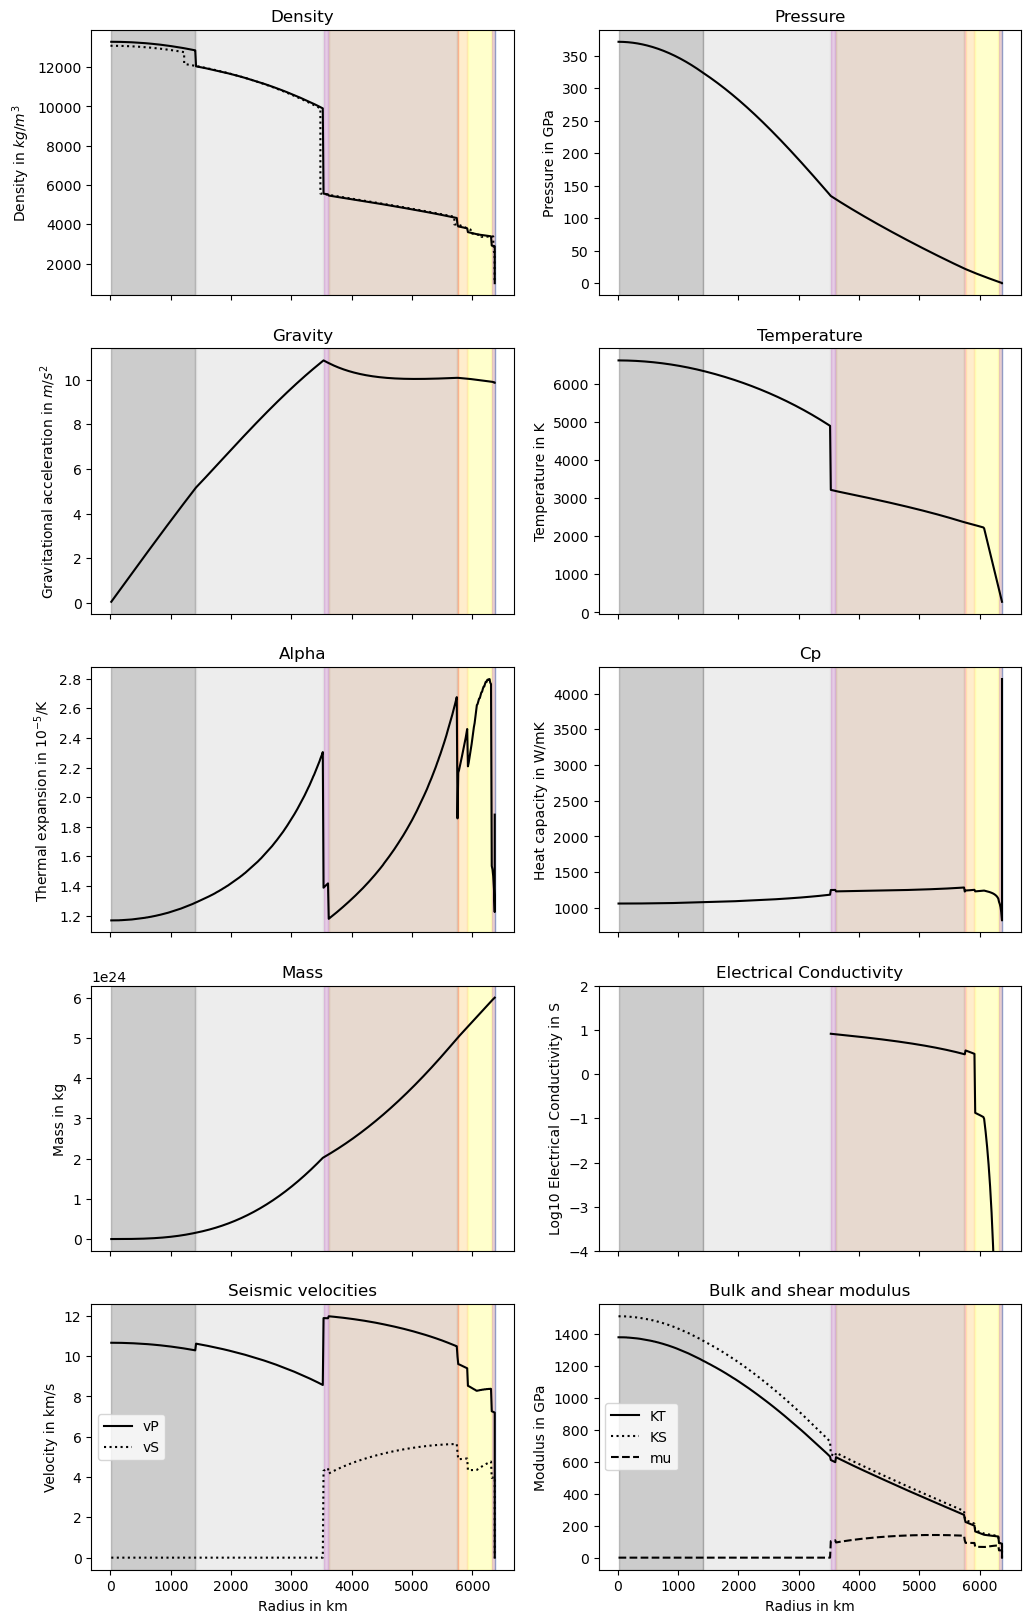

In [26]:
# To  earth 
T_p=temp_pla2(T_sol, r_s, 1.0); P_p=pressao(P_t, M_t, M_t, R_t, R_t, 3)
xelem_earth=np.array([0.0, 0.0, 0.2, 0.0])
if __name__ == "__main__":
    mass_obs = 1.00
    radius_obs = 1.00
    temp_obs = T_p
    P_p=P_p
    xelem=xelem_earth
    # STEP 1: Coarse search (quick - few points)
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, xelem, -1,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 
    
    # STEP 2: Refinement (around the best)
    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, xelem, -1,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  


Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 38.5, 0.02, temp_obs, P_p, xelem_earth, -1)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

visualization_earth(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [10]:
T_p=temp_pla2(T_sol, r_s, 1.0); P_p=pressao(P_t, M_t, M_t, R_t, R_t, 3)
xelem_earth=np.array([0.0, 0.0, 0.2, 0.0])
mass_obs = 1.00
radius_obs = 1.00
temp_obs = T_p
xelem=xelem_earth
best_Fe=38.5
best_H2O=0.02

0.5519417745529075 0.22119014935266243 11145.477628867115


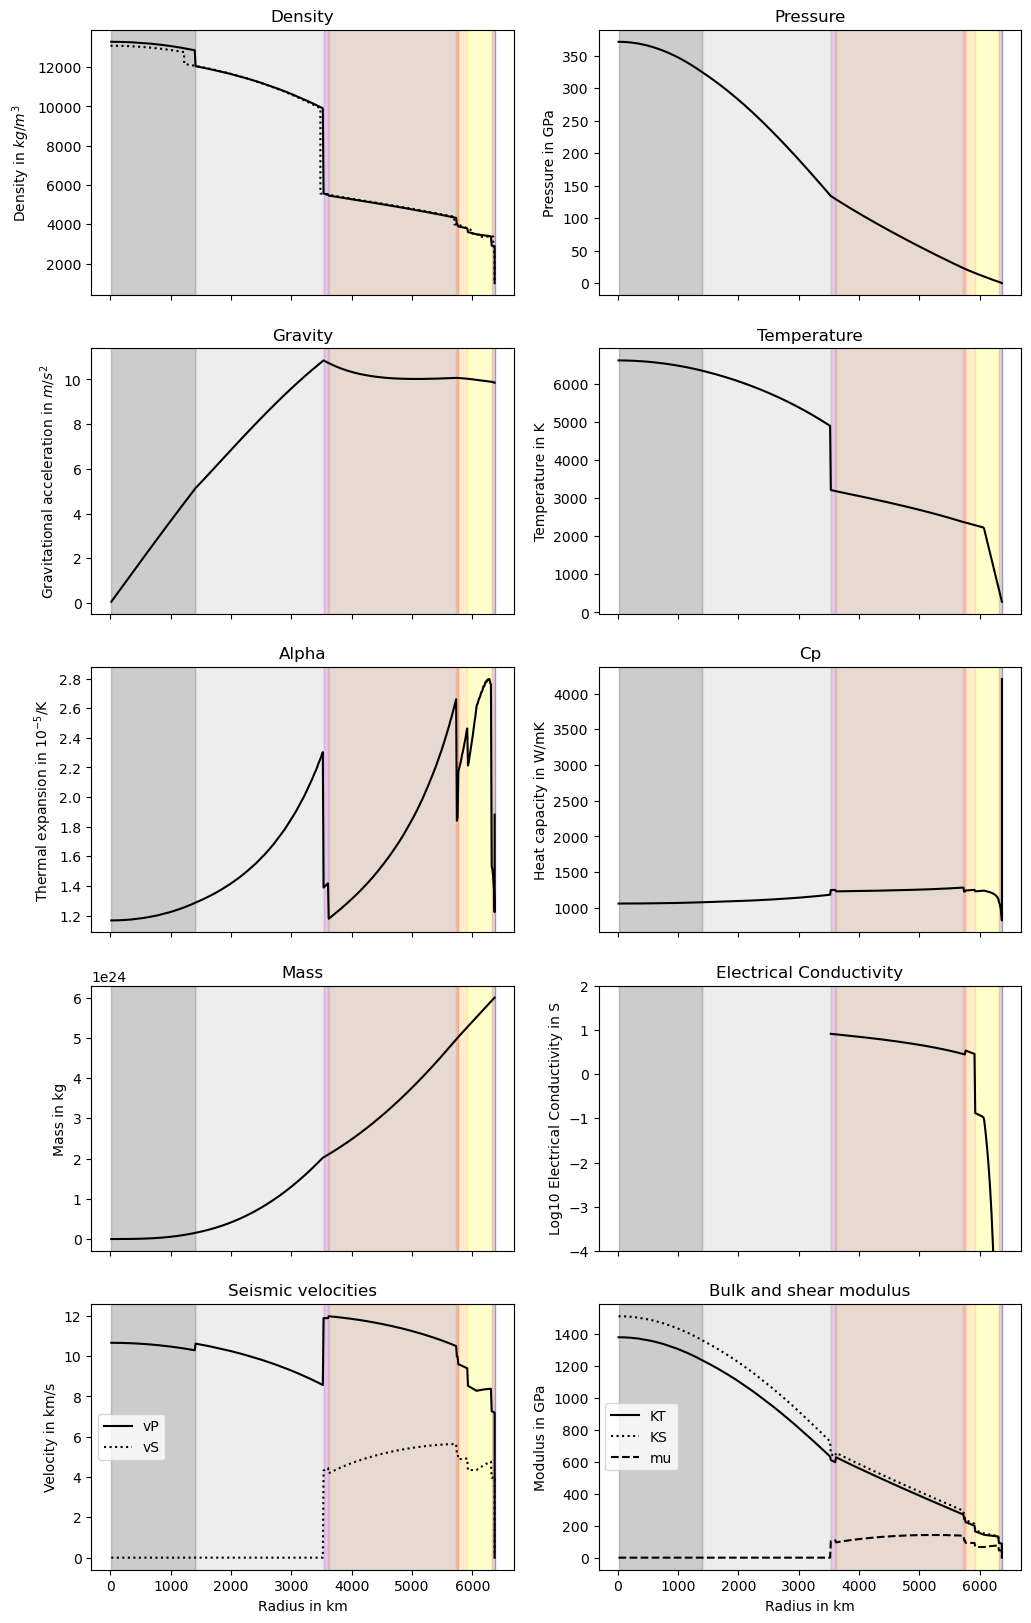

In [11]:
name='Terra'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 38.5, 0.1, temp_obs, P_p, xelem)

outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]


if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

D = Rc - Ric

if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")

visualization_earth(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(Rc/(radius_obs*R_t*1000), Ric/(radius_obs*R_t*1000), rho_core_mean)

STEP 1: Coarse search
Testing 144 combinations.
[1/144] Fe=10, H2O=0 -> R=1.003 R_E, M=0.8180 M_E, Combined relative error=0.0559
[2/144] Fe=10, H2O=10 -> R=1.059 R_E, M=0.8209 M_E, Combined relative error=0.1145
[3/144] Fe=10, H2O=20 -> R=1.092 R_E, M=0.8209 M_E, Combined relative error=0.1501
[4/144] Fe=10, H2O=30 -> R=1.124 R_E, M=0.8209 M_E, Combined relative error=0.1836
[5/144] Fe=10, H2O=40 -> R=1.152 R_E, M=0.8209 M_E, Combined relative error=0.2123
[6/144] Fe=10, H2O=50 -> R=1.178 R_E, M=0.8208 M_E, Combined relative error=0.2406
[7/144] Fe=10, H2O=60 -> R=1.203 R_E, M=0.8206 M_E, Combined relative error=0.2669
[8/144] Fe=10, H2O=70 -> R=1.227 R_E, M=0.8204 M_E, Combined relative error=0.2913
[9/144] Fe=10, H2O=80 -> R=1.249 R_E, M=0.8201 M_E, Combined relative error=0.3146
[10/144] Fe=15, H2O=0 -> R=0.992 R_E, M=0.8185 M_E, Combined relative error=0.0444
[11/144] Fe=15, H2O=10 -> R=1.048 R_E, M=0.8213 M_E, Combined relative error=0.1030
[12/144] Fe=15, H2O=20 -> R=1.082 R_E, 

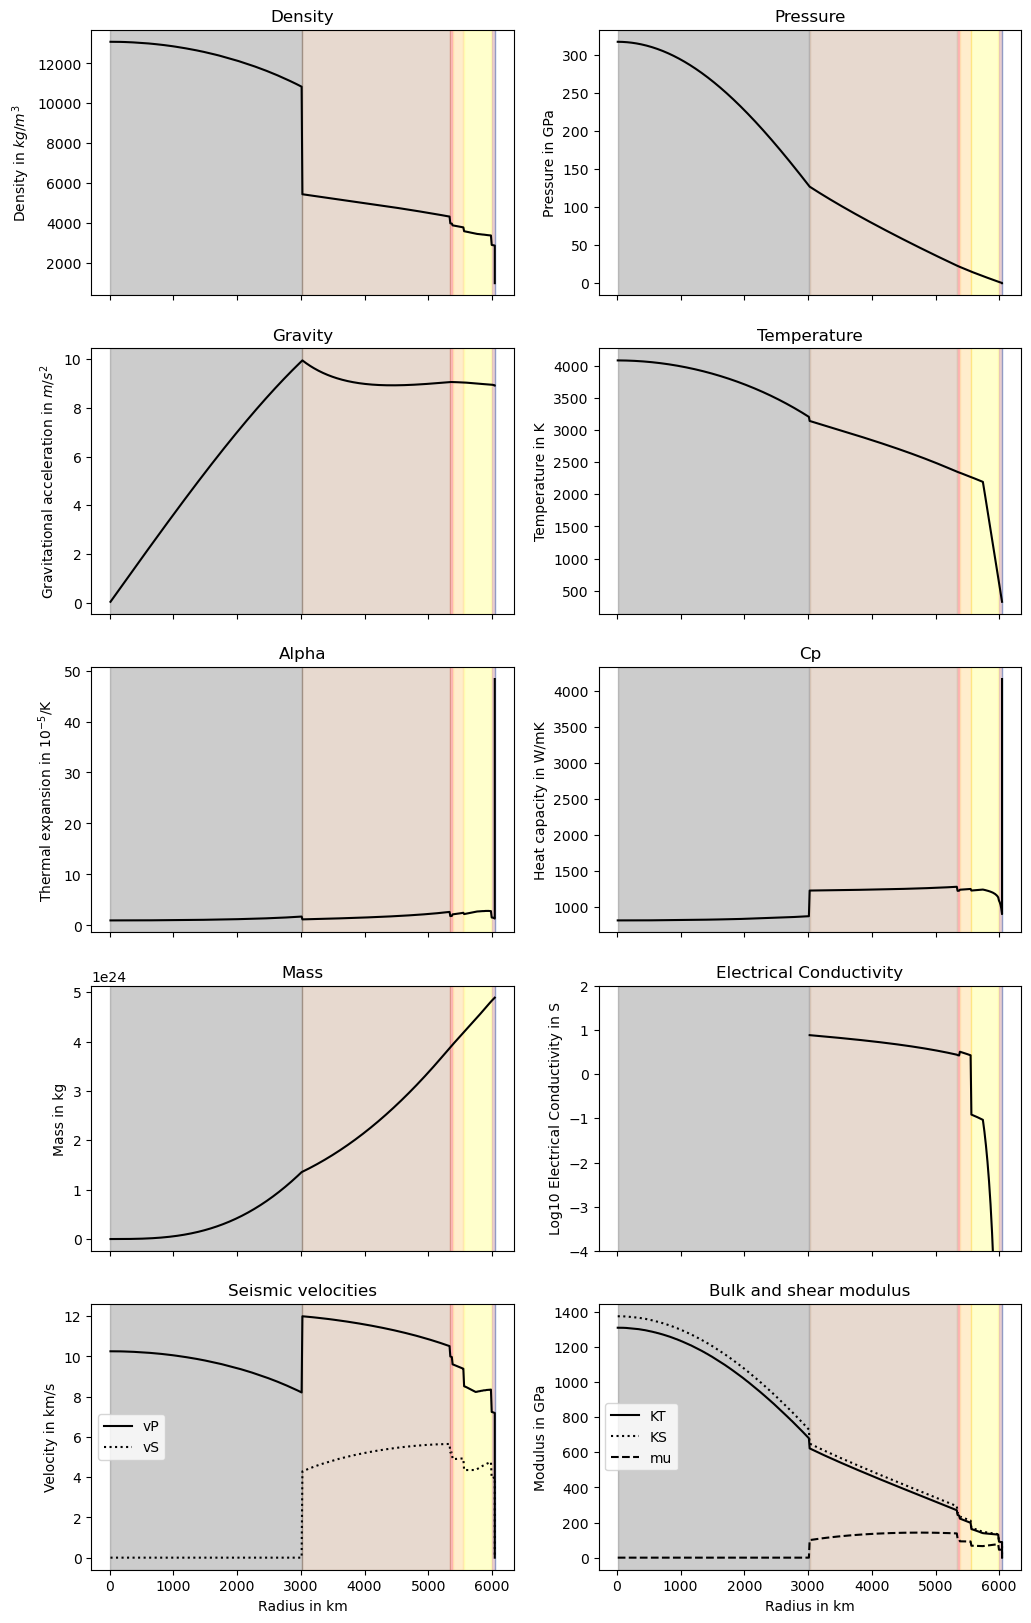

In [29]:
# to venus 
xelem_venus = np.array([0.0, 0.00, 0.08, 0.0])
# Reference value for S: AITTA, A. Venus’ internal structure, temperature and core composition. Icarus, v. 218, n. 2, p. 967-974, 2012.

T_p=temp_pla2(T_sol, r_s, 0.723)
P_p=pressao(P_t, 0.815*M_t, M_t, 0.95*R_t, R_t, 0)
if __name__ == "__main__":
    mass_obs = 0.815
    radius_obs = 0.95
    temp_obs = T_p
    xelem=xelem_venus
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, xelem, 330,
        fe_range=(10, 90, 5), h2o_range=(0, 90, 10)) 
    
    
    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, xelem, 330,delta_Fe=0.3*best_Fe, delta_H2O=0.3*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p, xelem, 60)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]


if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

D = Rc - Ric


if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")



visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)


print(D/(radius_obs*R_t*1000))

The planet does not have a liquid outer core
0.4972007049031642


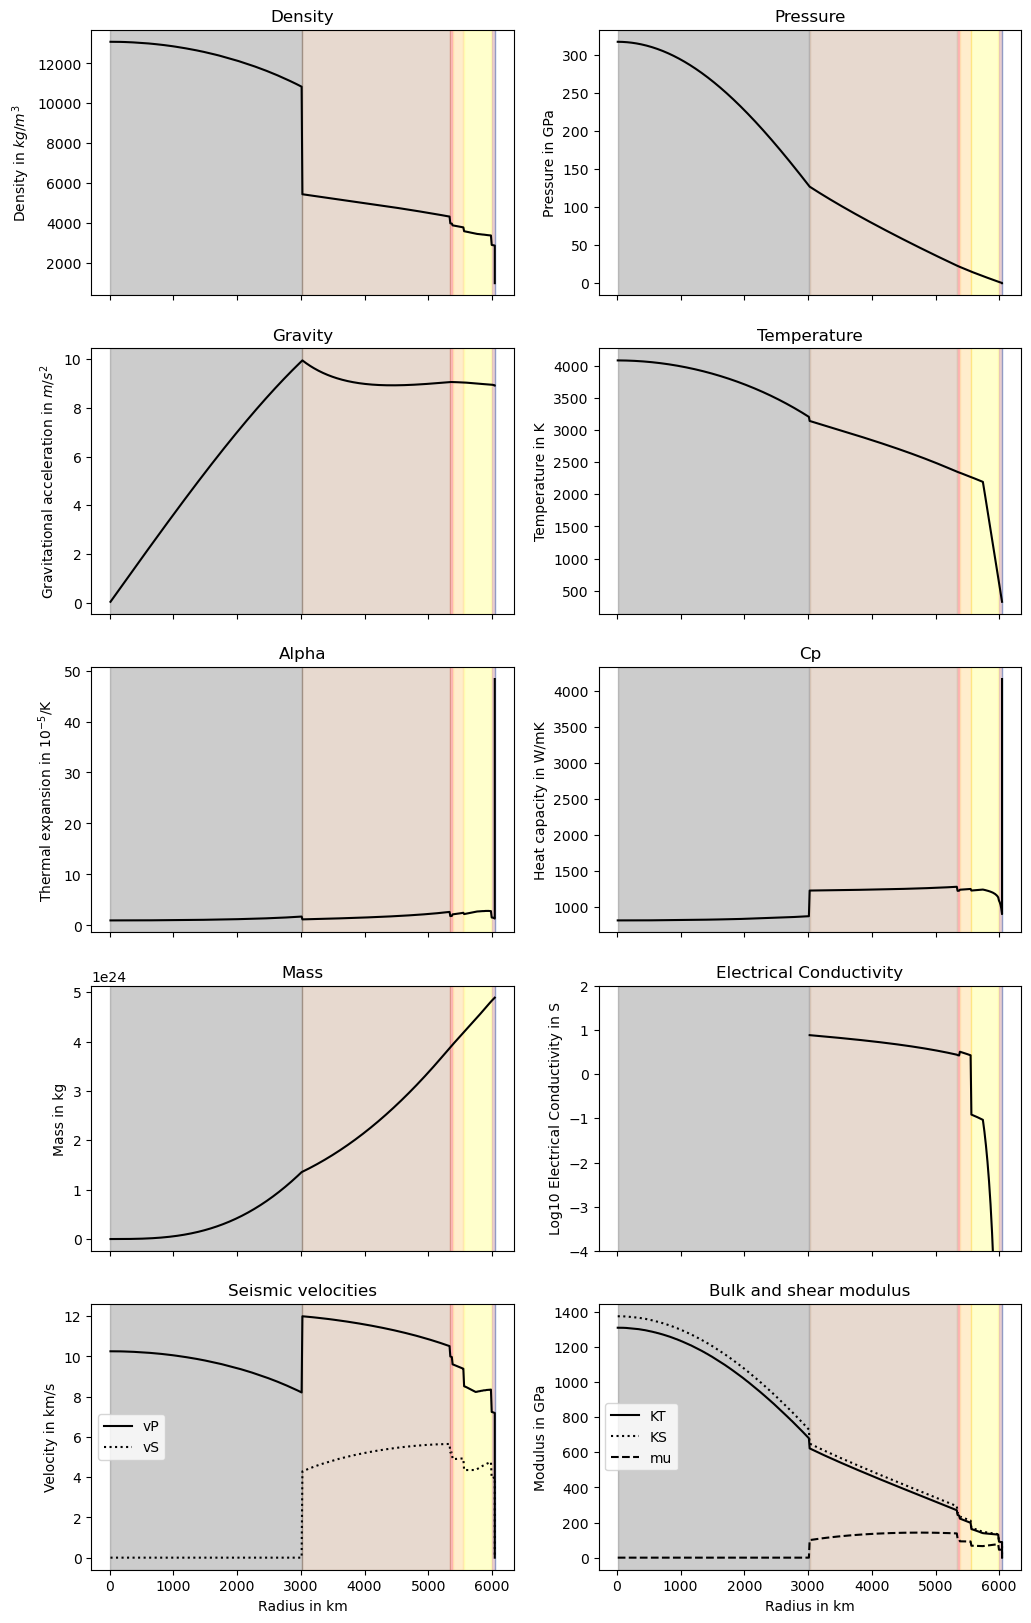

In [12]:
xelem_venus = np.array([0.0, 0.00, 0.08, 0.0])
# Reference value for S: AITTA, A. Venus’ internal structure, temperature and core composition. Icarus, v. 218, n. 2, p. 967-974, 2012.
P_p=pressao(P_t, 0.815*M_t, M_t, 0.95*R_t, R_t, 0)

mass_obs = 0.815
radius_obs = 0.95
temp_obs = temp_pla2(T_sol, r_s, 0.723)
xelem=xelem_venus
name='Venus'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 33.0, 0.1, temp_obs, P_p, xelem, 60)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]


if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

D = Rc - Ric


if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)


print(D/(radius_obs*R_t*1000))

STEP 1: Coarse search
Testing 144 combinations.
[1/144] Fe=10, H2O=0 -> R=0.446 R_E, M=0.0552 M_E, Combined relative error=0.1729
[2/144] Fe=10, H2O=10 -> R=0.478 R_E, M=0.0554 M_E, Combined relative error=0.2585
[3/144] Fe=10, H2O=20 -> R=0.503 R_E, M=0.0554 M_E, Combined relative error=0.3236
[4/144] Fe=10, H2O=30 -> R=0.524 R_E, M=0.0554 M_E, Combined relative error=0.3798
[5/144] Fe=10, H2O=40 -> R=0.543 R_E, M=0.0554 M_E, Combined relative error=0.4299
[6/144] Fe=10, H2O=50 -> R=0.561 R_E, M=0.0554 M_E, Combined relative error=0.4764
[9/144] Fe=10, H2O=80 -> R=0.608 R_E, M=0.0554 M_E, Combined relative error=0.6008
[10/144] Fe=15, H2O=0 -> R=0.441 R_E, M=0.0552 M_E, Combined relative error=0.1593
[11/144] Fe=15, H2O=10 -> R=0.474 R_E, M=0.0554 M_E, Combined relative error=0.2464
[12/144] Fe=15, H2O=20 -> R=0.499 R_E, M=0.0555 M_E, Combined relative error=0.3122
[13/144] Fe=15, H2O=30 -> R=0.520 R_E, M=0.0555 M_E, Combined relative error=0.3689
[14/144] Fe=15, H2O=40 -> R=0.539 R_E

C:\Users\vitor\AppData\Local\Temp\ipykernel_24668\213928631.py:73: RuntimeWarning: invalid value encountered in scalar power
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius


[55/144] Fe=40, H2O=0 -> R=0.413 R_E, M=0.0553 M_E, Combined relative error=0.0872
[56/144] Fe=40, H2O=10 -> R=0.449 R_E, M=0.0555 M_E, Combined relative error=0.1820
[57/144] Fe=40, H2O=20 -> R=0.476 R_E, M=0.0555 M_E, Combined relative error=0.2519
[58/144] Fe=40, H2O=30 -> R=0.498 R_E, M=0.0555 M_E, Combined relative error=0.3112
[59/144] Fe=40, H2O=40 -> R=0.518 R_E, M=0.0555 M_E, Combined relative error=0.3642
[60/144] Fe=40, H2O=50 -> R=0.537 R_E, M=0.0555 M_E, Combined relative error=0.4121
[61/144] Fe=40, H2O=60 -> R=0.553 R_E, M=0.0555 M_E, Combined relative error=0.4560
[62/144] Fe=40, H2O=70 -> R=0.582 R_E, M=0.0500 M_E, Combined relative error=0.5387
[63/144] Fe=40, H2O=80 -> ERRO: cannot convert float NaN to integer
[64/144] Fe=45, H2O=0 -> R=0.407 R_E, M=0.0553 M_E, Combined relative error=0.0716
[65/144] Fe=45, H2O=10 -> R=0.444 R_E, M=0.0555 M_E, Combined relative error=0.1682
[66/144] Fe=45, H2O=20 -> R=0.471 R_E, M=0.0555 M_E, Combined relative error=0.2393
[67/144] F

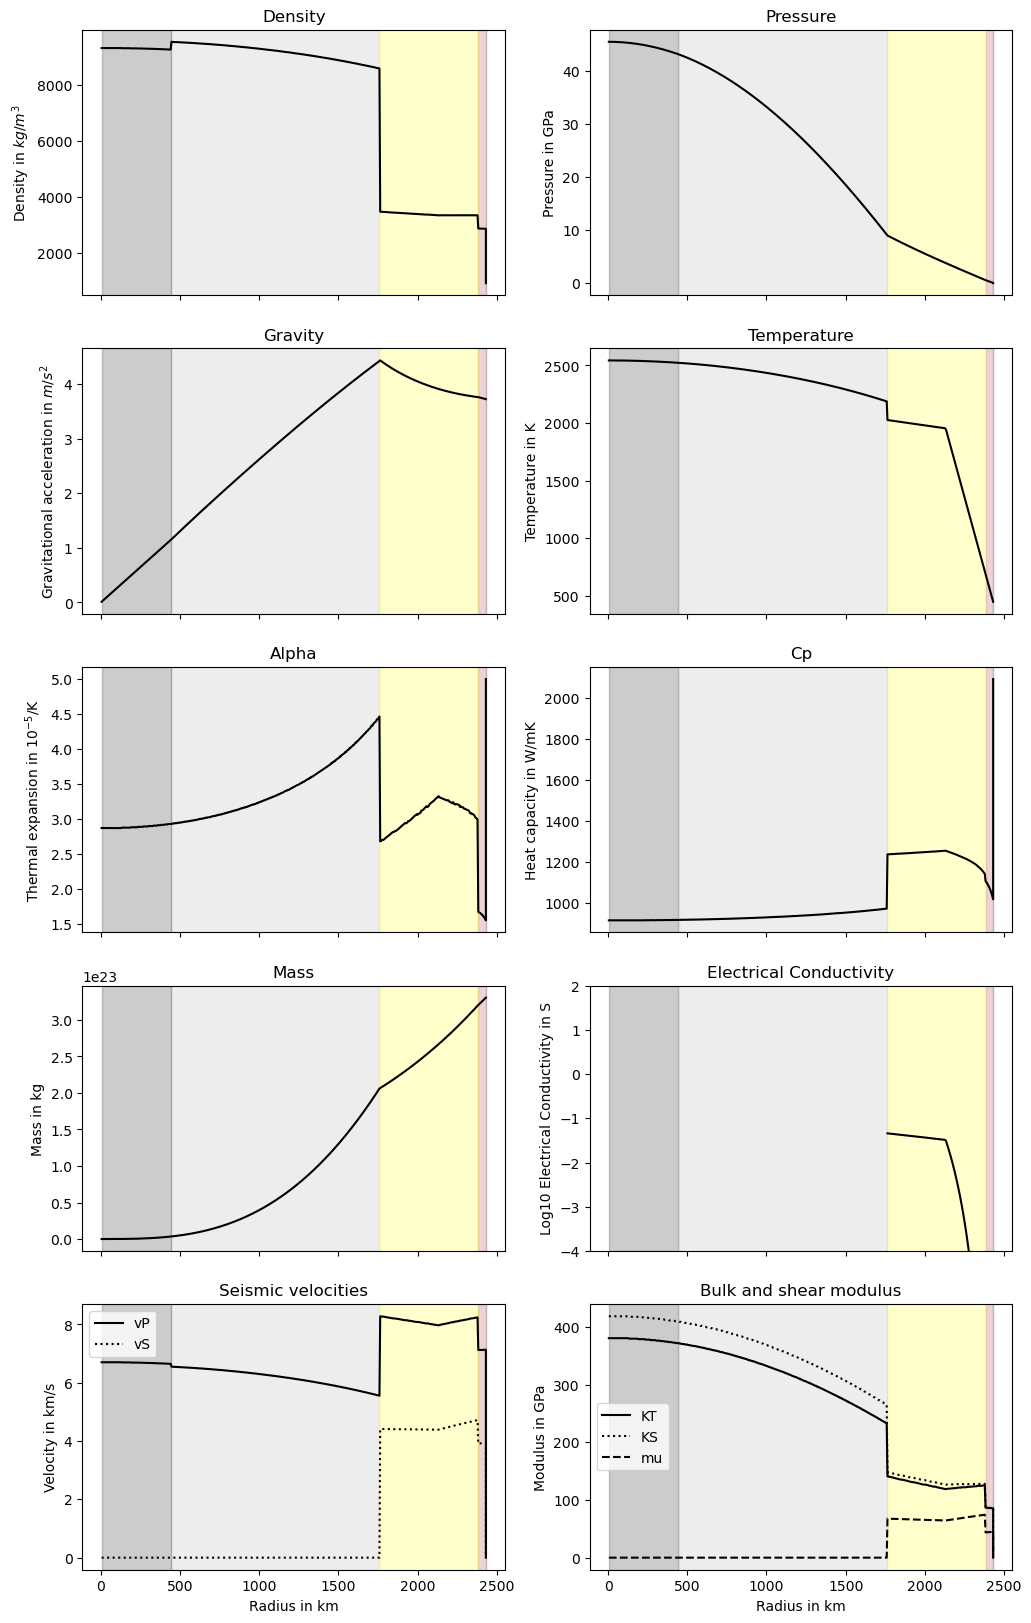

In [32]:
# To mercury 
xelem_mercury = np.array([0.0, 0.0, 0.02, 0.0]) 
# Referencia para o valor de S: RIVOLDINI, Attilio; VAN HOOLST, Tim; VERHOEVEN, Olivier. The interior structure of Mercury and its core sulfur content. Icarus, v. 201, n. 1, p. 12-30, 2009.
T_p=temp_pla2(T_sol, r_s, 0.387)
P_p=pressao(P_t, 0.055*M_t, M_t, 0.38*R_t, R_t, 1)
if __name__ == "__main__":
    mass_obs = 0.055
    radius_obs = 0.38
    temp_obs = T_p
    xelem=xelem_mercury
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, xelem, -0.3,
        fe_range=(10, 90, 5), h2o_range=(0, 90, 10)) 
    
    
    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, xelem, -0.3,delta_Fe=0.3*best_Fe, delta_H2O=0.3*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p, xelem, -1)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]


if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

D = Rc - Ric

if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    print(D/(radius_obs*R_t*1000), rho_core_mean)
else:
    print("The planet does not have a liquid outer core")
    print(D/(radius_obs*R_t*1000))


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

In [13]:
xelem_mercury = np.array([0.0, 0.0, 0.02, 0.0])
P_p=pressao(P_t, 0.055*M_t, M_t, 0.38*R_t, R_t, 1)
mass_obs = 0.055
radius_obs = 0.38
temp_obs = temp_pla2(T_sol, r_s, 0.387)
xelem=xelem_mercury

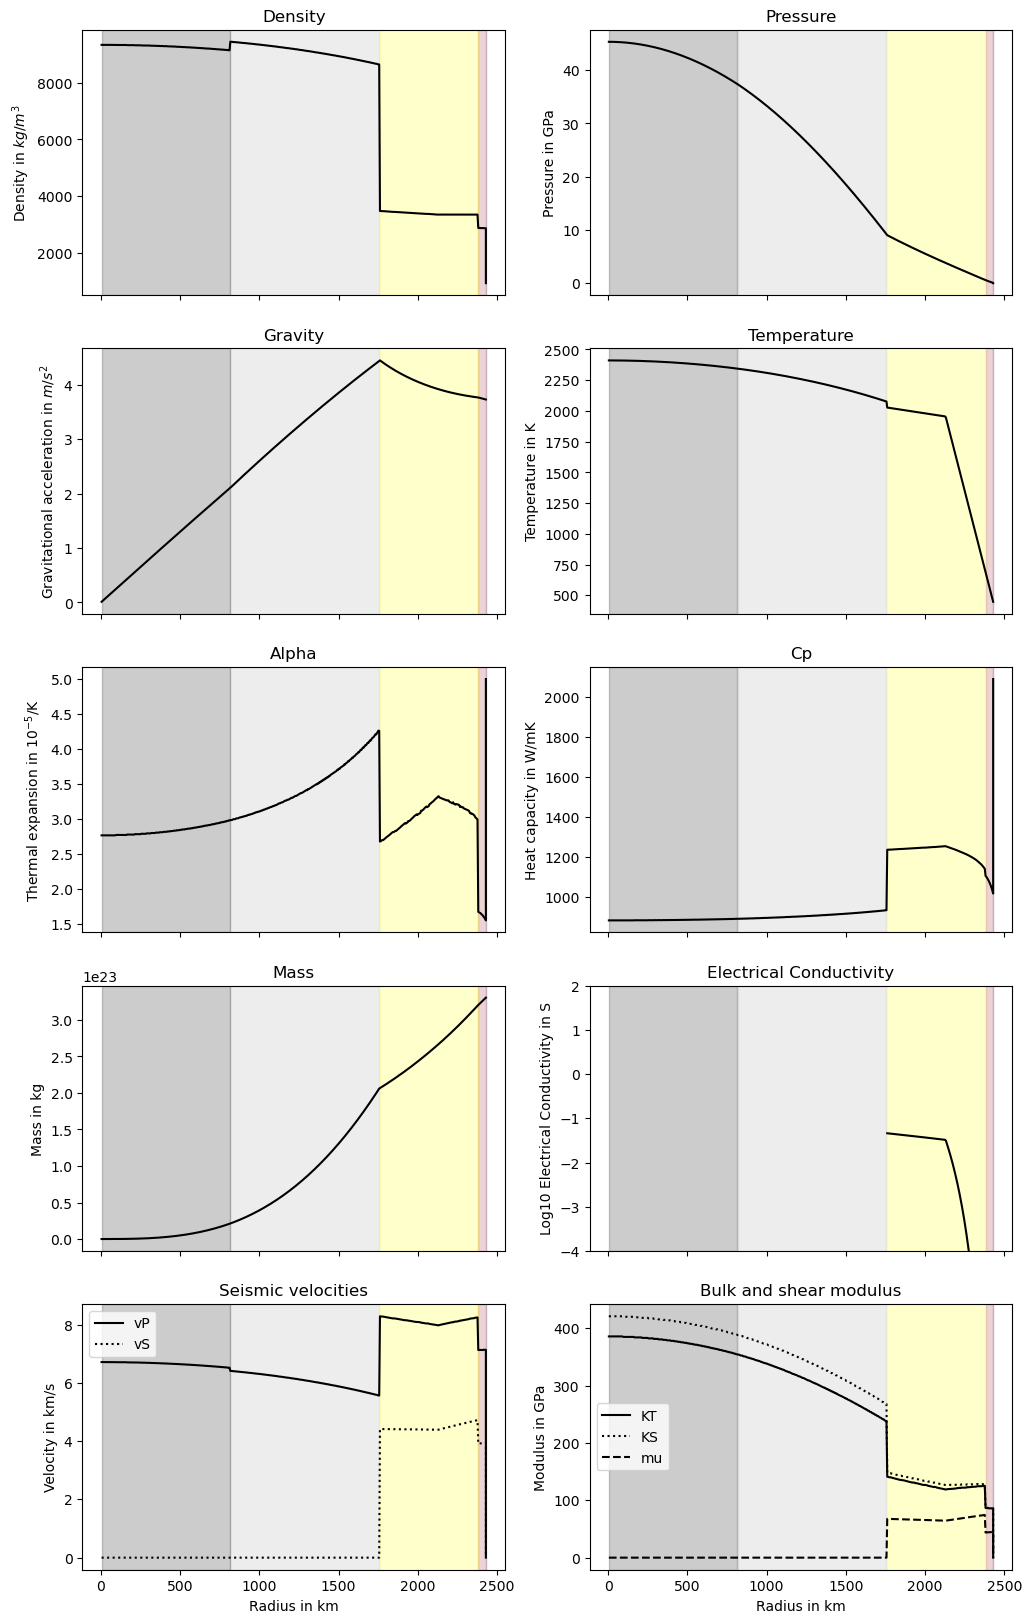

In [14]:
name='mercury'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 65.0, 0.075, temp_obs, P_p, xelem, -0.3)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]


if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

D = Rc - Ric

if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

STEP 1: Coarse search
Testing 144 combinations.
[1/144] Fe=10, H2O=0 -> R=0.551 R_E, M=0.1074 M_E, Combined relative error=0.0356
[2/144] Fe=10, H2O=10 -> R=0.582 R_E, M=0.1077 M_E, Combined relative error=0.0936
[3/144] Fe=10, H2O=20 -> R=0.604 R_E, M=0.1077 M_E, Combined relative error=0.1363
[4/144] Fe=10, H2O=30 -> R=0.623 R_E, M=0.1077 M_E, Combined relative error=0.1704
[5/144] Fe=10, H2O=40 -> R=0.639 R_E, M=0.1077 M_E, Combined relative error=0.2019
[6/144] Fe=10, H2O=50 -> R=0.655 R_E, M=0.1077 M_E, Combined relative error=0.2314
[7/144] Fe=10, H2O=60 -> R=0.670 R_E, M=0.1077 M_E, Combined relative error=0.2592
[8/144] Fe=10, H2O=70 -> R=0.684 R_E, M=0.1077 M_E, Combined relative error=0.2858
[9/144] Fe=10, H2O=80 -> R=0.697 R_E, M=0.1077 M_E, Combined relative error=0.3105
[10/144] Fe=15, H2O=0 -> R=0.545 R_E, M=0.1074 M_E, Combined relative error=0.0251
[11/144] Fe=15, H2O=10 -> R=0.576 R_E, M=0.1078 M_E, Combined relative error=0.0838
[12/144] Fe=15, H2O=20 -> R=0.599 R_E, 

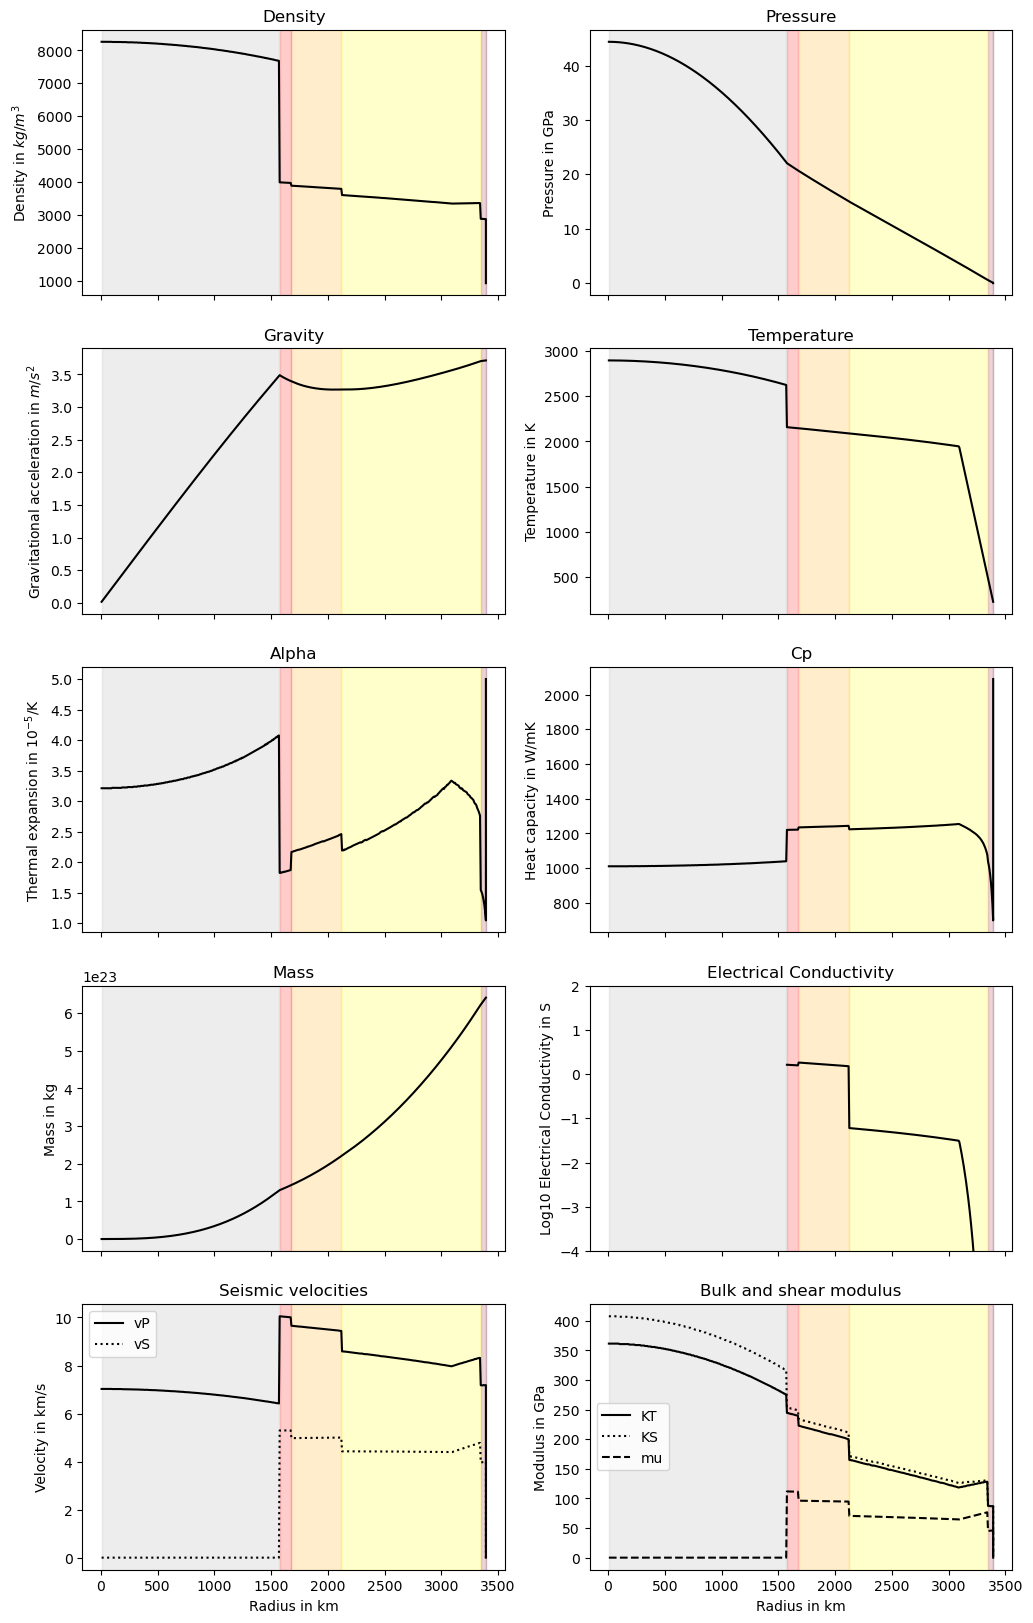

In [35]:
# To mars
xelem_mars = np.array([0.0, 0.0, 0.25, 0.0])
# Referencia para o valor de S:RIVOLDINI, A. et al. Geodesy constraints on the interior structure and composition of Mars. Icarus, v. 213, n. 2, p. 451-472, 2011.
T_p=temp_pla2(T_sol, r_s, 1.524)
P_p=pressao(P_t, 0.107*M_t, M_t, 0.532*R_t, R_t, 2)
if __name__ == "__main__":
    mass_obs = 0.107
    radius_obs = 0.532
    temp_obs = T_p
    xelem=xelem_mars
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, xelem, -1,
        fe_range=(10, 90, 5), h2o_range=(0, 90, 10)) 
    
    
    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, xelem,-1,delta_Fe=0.3*best_Fe, delta_H2O=0.3*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p, xelem, -1)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]


if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

D = Rc - Ric

if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    print(D/(radius_obs*R_t*1000), rho_core_mean)
else:
    print("The planet does not have a liquid outer core")
    print(D/(radius_obs*R_t*1000))


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

In [15]:
xelem_mars = np.array([0.0, 0.0, 0.25, 0.0])
T_p=temp_pla2(T_sol, r_s, 1.524)
P_p=pressao(P_t, 0.107*M_t, M_t, 0.532*R_t, R_t, 2)

mass_obs = 0.107
radius_obs = 0.532
temp_obs = T_p
xelem=xelem_mars

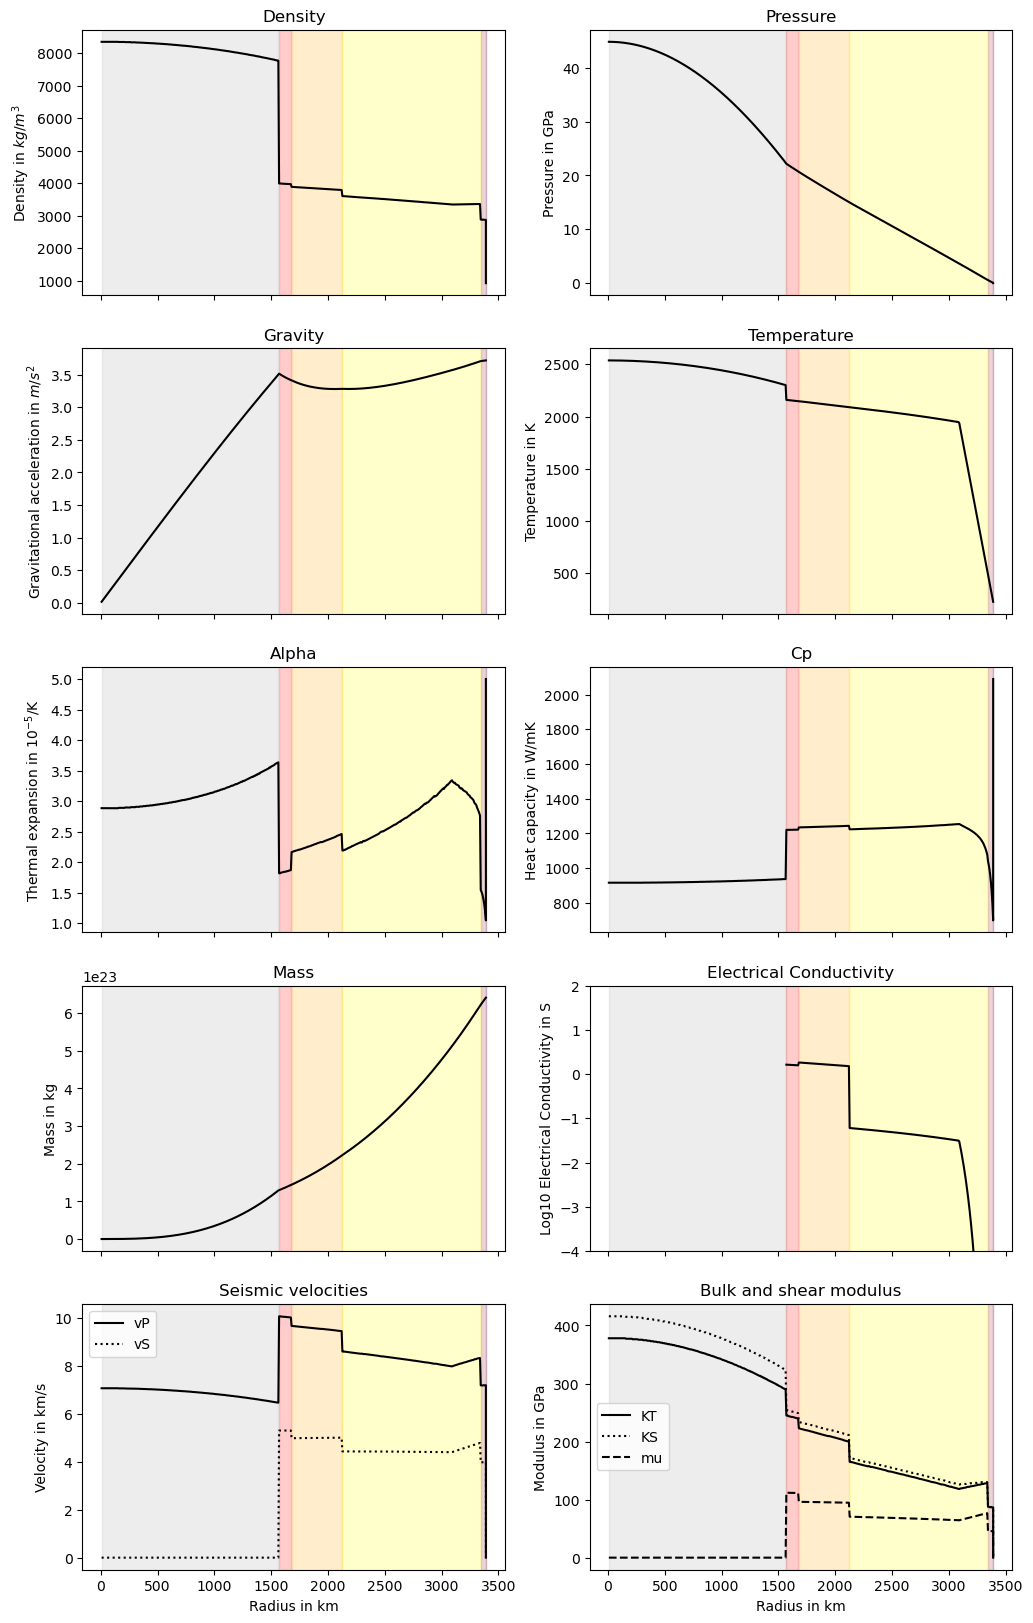

In [16]:
name='mars'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 26.0, 0.125, temp_obs, P_p, xelem, -0.3)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]


if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

D = Rc - Ric

if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

STEP 1: Coarse search
Testing 144 combinations.


C:\Users\vitor\0 ROWS_Interior-Structure-Model-main\ROWS_Interior-Structure-Model-main\EOS_functions.py:253: RuntimeWarning: divide by zero encountered in scalar divide
  dV = p.V0 * 0.5 * abs(P_i-Pr)/max(P_i,Pr)  # if Pi, Pr very close together, then start with smaller dV
C:\Users\vitor\0 ROWS_Interior-Structure-Model-main\ROWS_Interior-Structure-Model-main\EOS_functions.py:253: RuntimeWarning: invalid value encountered in scalar divide
  dV = p.V0 * 0.5 * abs(P_i-Pr)/max(P_i,Pr)  # if Pi, Pr very close together, then start with smaller dV


[1/144] Fe=10, H2O=0 -> R=0.273 R_E, M=0.0123 M_E, Combined relative error=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 0.0000 wt%
Combined relative error mínimo = 0.0114
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=10.0000, H2O=0.0000
Range Fe: 7.0000 to 13.0000 (step=0.5000)
Range H2O: 0.0000 to 0.2500 (step=0.0250)
Total number of combinations: 13 × 11 = 143
Testing 143 combinations.
[1/143] Fe=7.0, H2O=0.0 -> ERRO: name 'iron_number' is not defined
[2/143] Fe=7.0, H2O=0.025 -> ERRO: name 'iron_number' is not defined
[3/143] Fe=7.0, H2O=0.05 -> ERRO: name 'iron_number' is not defined
[4/143] Fe=7.0, H2O=0.07500000000000001 -> ERRO: name 'iron_number' is not defined
[5/143] Fe=7.0, H2O=0.1 -> ERRO: name 'iron_number' is not defined
[6/143] Fe=7.0, H2O=0.125 -> ERRO: name 'iron_number' is not defined
[7/143] Fe=7.0, H2O=0.15000000000000002 -> ERRO: name 'iron_number' is not defined
[8/143] Fe=7.0, H2

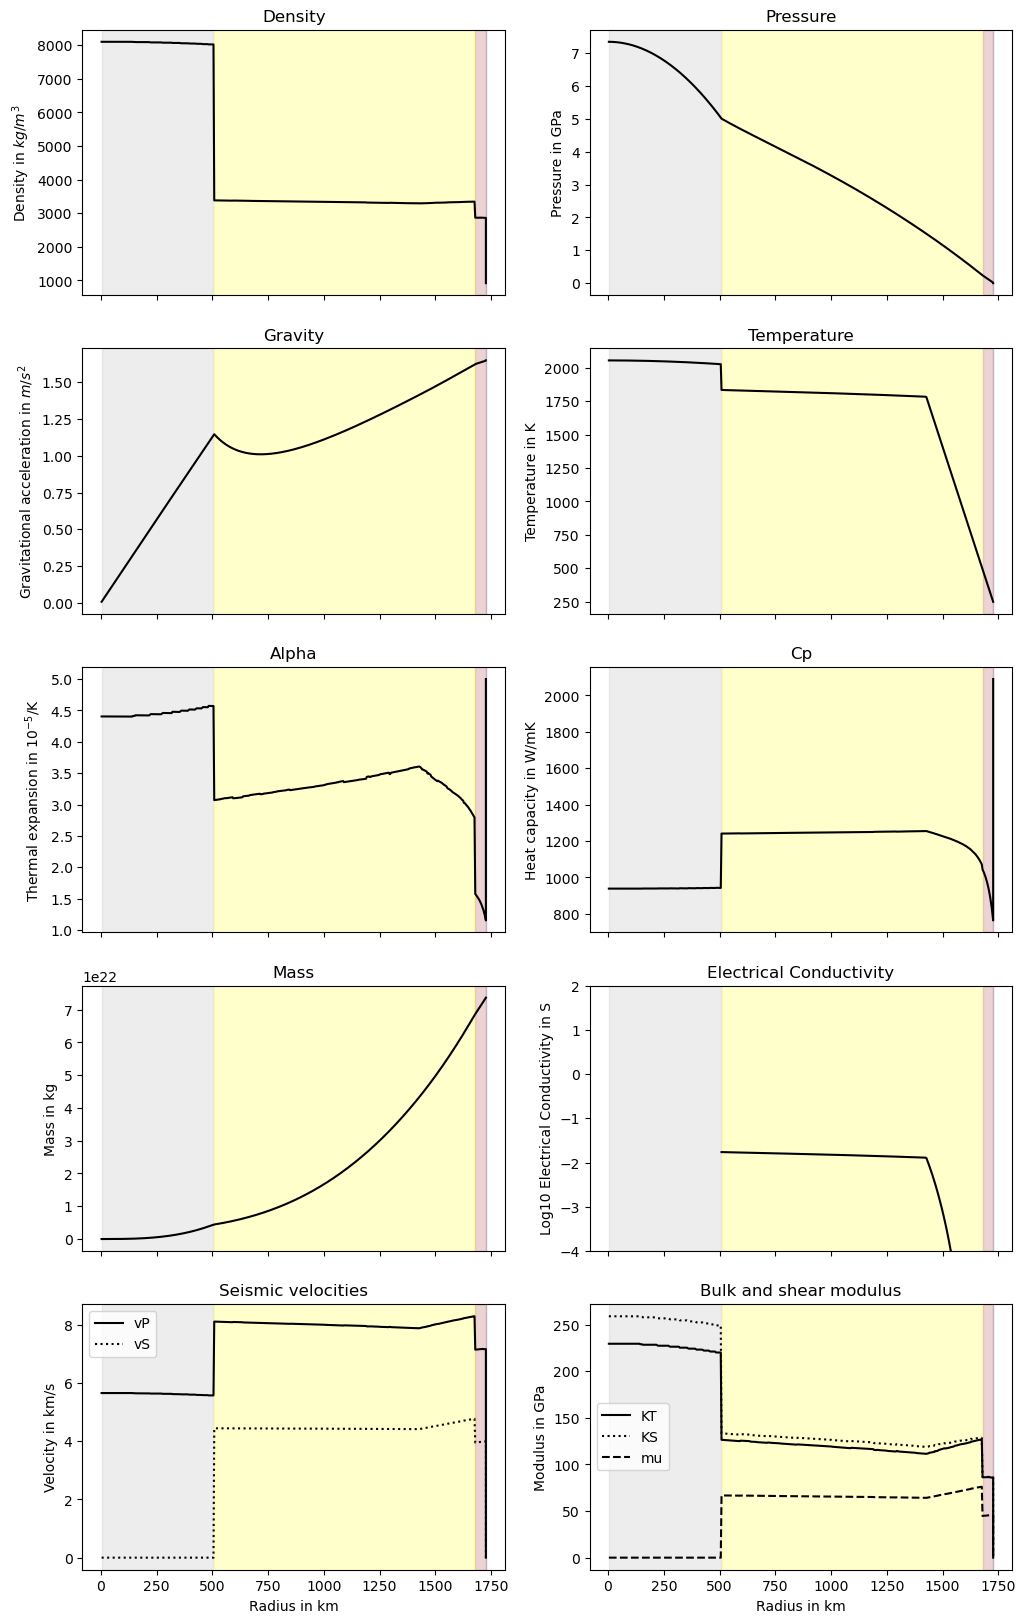

In [38]:
# To moon 
xelem_moon = np.array([0.0, 0.0, 0.10, 0.0])
# Referencia para o valor de S: WEBER, Renee C. et al. Seismic detection of the lunar core. science, v. 331, n. 6015, p. 309-312, 2011.
if __name__ == "__main__":
    mass_obs = 0.0123
    radius_obs = 0.27
    temp_obs = 250
    P_p=0
    xelem=xelem_moon
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, xelem, -1,
        fe_range=(10, 90, 5), h2o_range=(0, 90, 10)) 
    
    
    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, xelem, -1,delta_Fe=0.3*best_Fe, delta_H2O=0.3*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p, xelem)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]


if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

D = Rc - Ric

if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    print(D/(radius_obs*R_t*1000), rho_core_mean)
else:
    print("The planet does not have a liquid outer core")
    print(D/(radius_obs*R_t*1000))

visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)


In [17]:
xelem_moon = np.array([0.0, 0.0, 0.10, 0.0])
mass_obs = 0.0123
radius_obs = 0.27
temp_obs = 250
P_p=0
xelem=xelem_moon

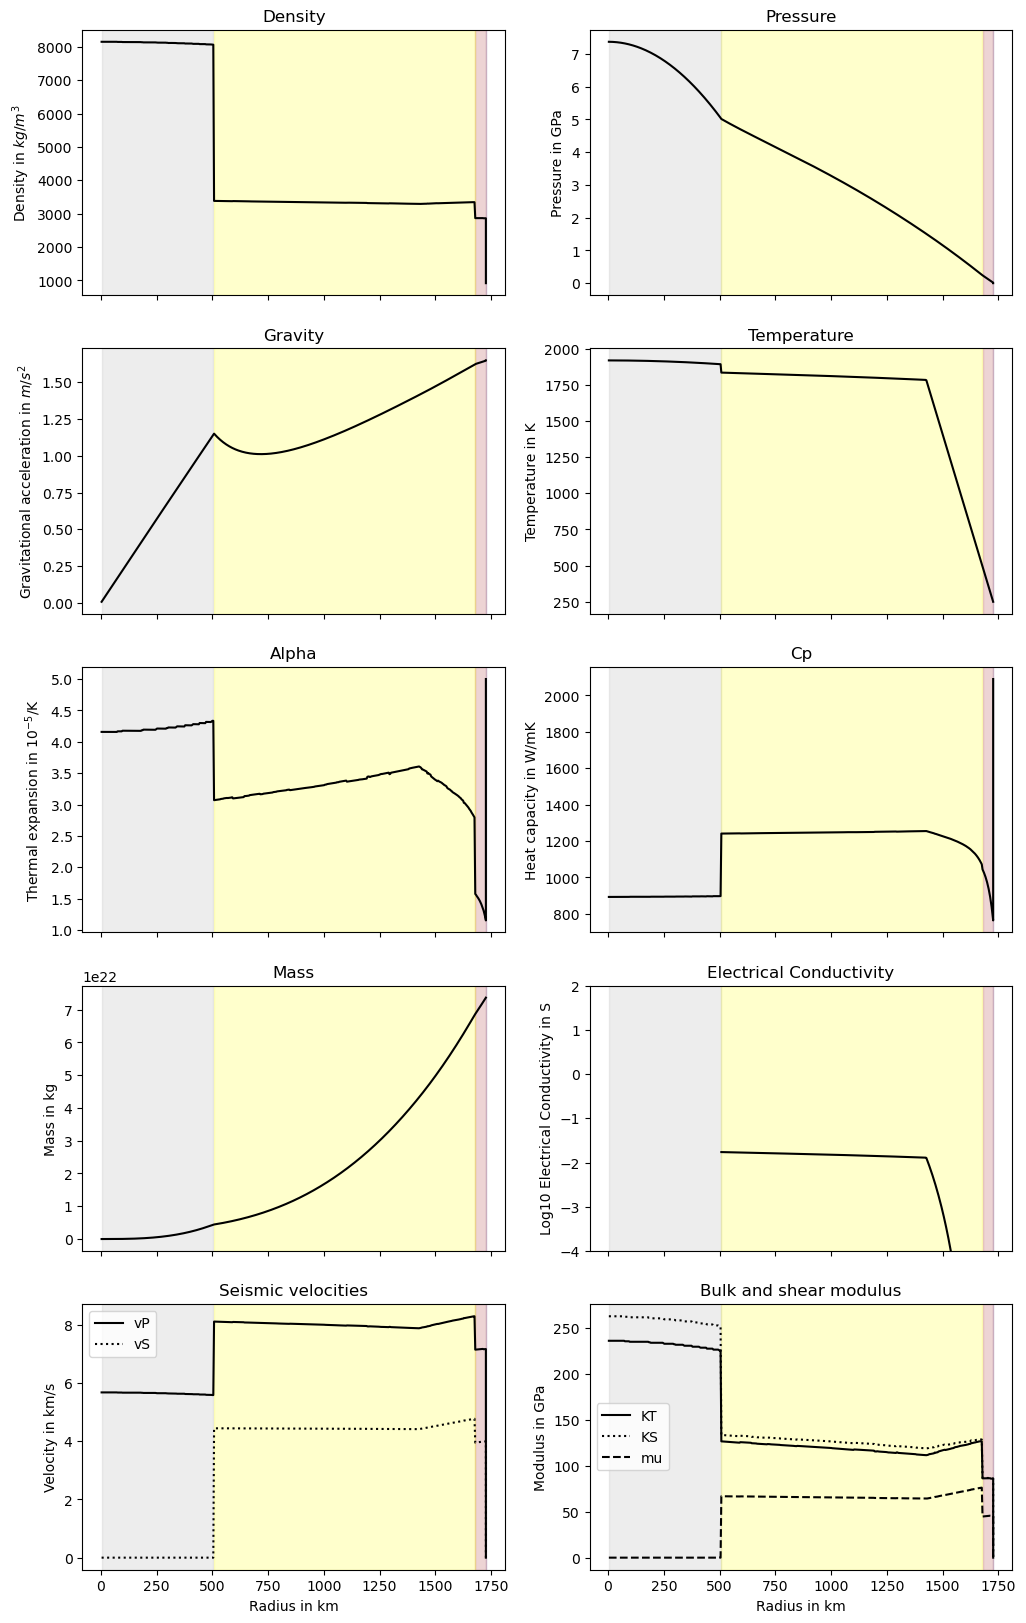

In [18]:
name='moon'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 13.0, 0.125, temp_obs, P_p, xelem, -0.3)

outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

D = Rc - Ric

if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)



STEP 1: Coarse search
Testing 144 combinations.
[1/144] Fe=10, H2O=0 -> R=0.237 R_E, M=0.0080 M_E, Combined relative error=0.0529
[2/144] Fe=10, H2O=10 -> R=0.256 R_E, M=0.0081 M_E, Combined relative error=0.0240
[3/144] Fe=10, H2O=20 -> R=0.267 R_E, M=0.0081 M_E, Combined relative error=0.0680
[4/144] Fe=10, H2O=30 -> R=0.277 R_E, M=0.0081 M_E, Combined relative error=0.1079
[5/144] Fe=10, H2O=40 -> R=0.286 R_E, M=0.0081 M_E, Combined relative error=0.1450
[6/144] Fe=10, H2O=50 -> R=0.295 R_E, M=0.0081 M_E, Combined relative error=0.1803
[7/144] Fe=10, H2O=60 -> R=0.303 R_E, M=0.0081 M_E, Combined relative error=0.2139
[8/144] Fe=10, H2O=70 -> R=0.311 R_E, M=0.0081 M_E, Combined relative error=0.2455
[9/144] Fe=10, H2O=80 -> R=0.319 R_E, M=0.0081 M_E, Combined relative error=0.2758
[10/144] Fe=15, H2O=0 -> R=0.234 R_E, M=0.0080 M_E, Combined relative error=0.0626
[11/144] Fe=15, H2O=10 -> R=0.254 R_E, M=0.0081 M_E, Combined relative error=0.0162
[12/144] Fe=15, H2O=20 -> R=0.265 R_E, 

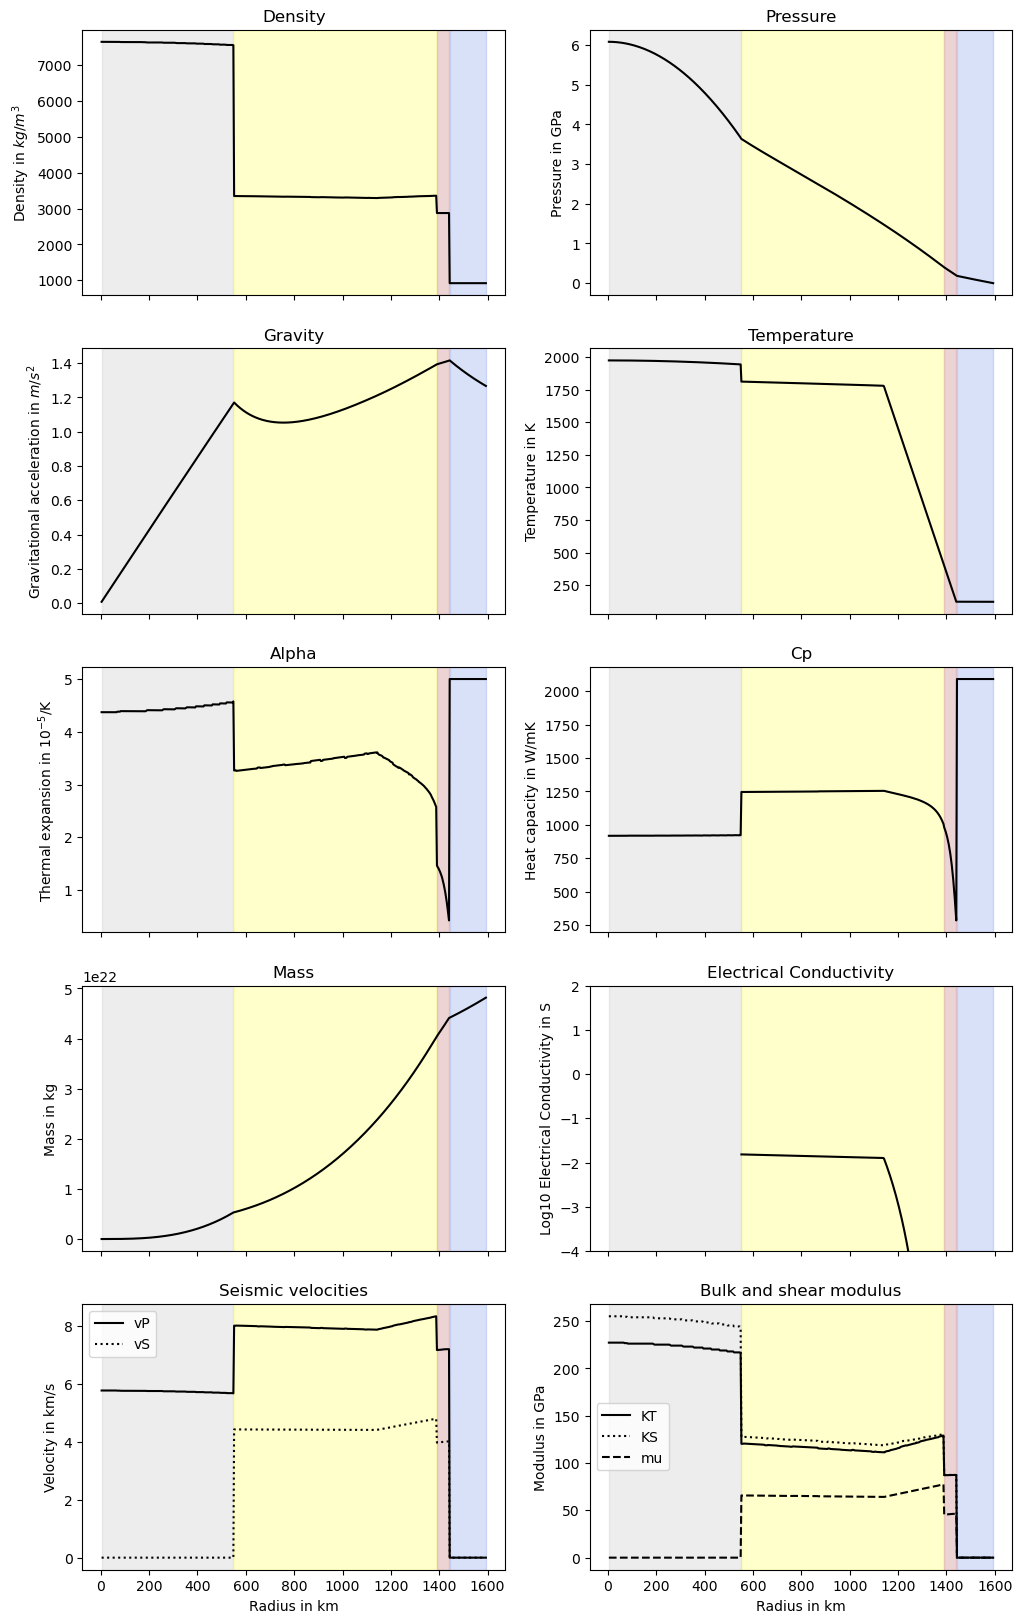

In [41]:
# Para  Europa
xelem_europa = np.array([0.0, 0.0, 0.18, 0.0])
# Referencia para o valor S: SOHL, F. et al. Implications from Galileo observations on the interior structure and chemistry of the Galilean satellites. Icarus, v. 157, n. 1, p. 104-119, 2002.
# Valor presente na figure 5 do artigo.
if __name__ == "__main__":
    mass_obs = 0.008
    radius_obs = 0.25
    temp_obs=temp_pla2(T_sol, r_s, 5.2)
    P_p=0
    xelem=xelem_europa
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, xelem, -1,
        fe_range=(10, 90, 5), h2o_range=(0, 90, 10)) 
    
    
    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, xelem, -1,delta_Fe=0.3*best_Fe, delta_H2O=0.3*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p, xelem)

outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

D = Rc - Ric

if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    print(D/(radius_obs*R_t*1000), rho_core_mean)
else:
    print("The planet does not have a liquid outer core")
    print(D/(radius_obs*R_t*1000))


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

In [19]:
xelem_europa = np.array([0.0, 0.0, 0.18, 0.0])
mass_obs = 0.008
radius_obs = 0.25
temp_obs=temp_pla2(T_sol, r_s, 5.2)
P_p=0
xelem=xelem_europa

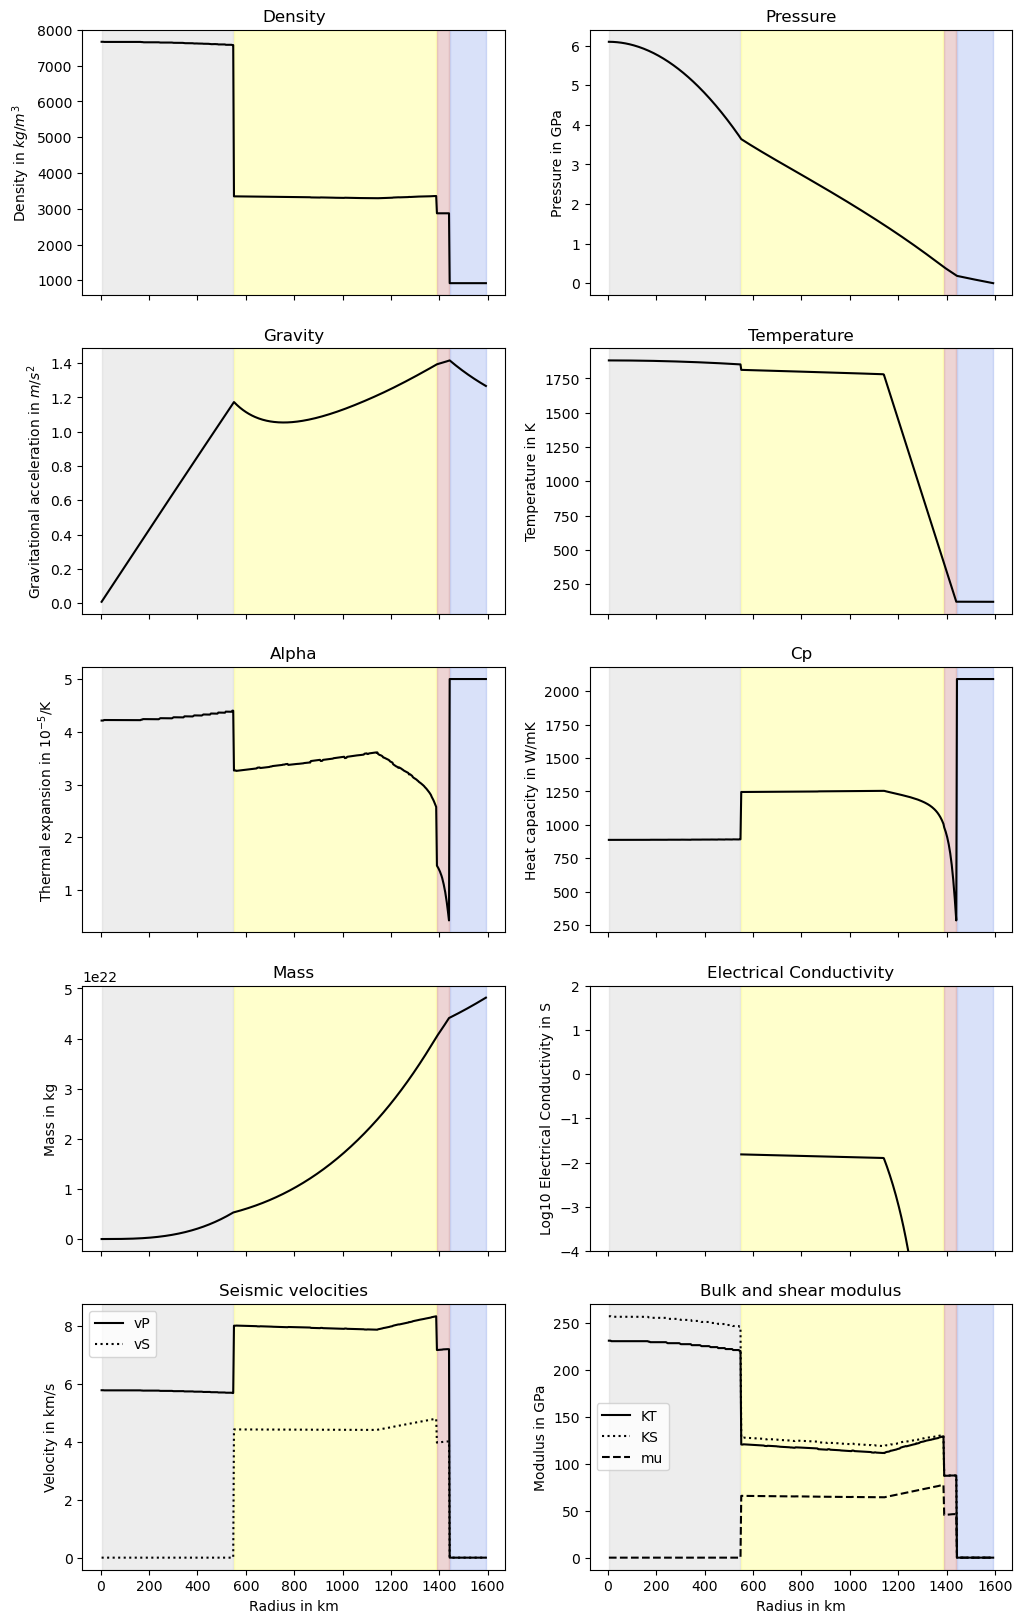

In [20]:
name='europa'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 17.0, 8.5, temp_obs, P_p, xelem, -0.3)

outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

D = Rc - Ric

if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")



visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

STEP 1: Coarse search
Testing 144 combinations.
[1/144] Fe=10, H2O=0 -> R=0.311 R_E, M=0.0184 M_E, Combined relative error=0.1814
[2/144] Fe=10, H2O=10 -> R=0.332 R_E, M=0.0184 M_E, Combined relative error=0.1256
[3/144] Fe=10, H2O=20 -> R=0.346 R_E, M=0.0184 M_E, Combined relative error=0.0890
[4/144] Fe=10, H2O=30 -> R=0.359 R_E, M=0.0184 M_E, Combined relative error=0.0560
[5/144] Fe=10, H2O=40 -> R=0.371 R_E, M=0.0184 M_E, Combined relative error=0.0258
[6/144] Fe=10, H2O=50 -> R=0.382 R_E, M=0.0184 M_E, Combined relative error=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 50.0000 wt%
Combined relative error mínimo = 0.0084
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=10.0000, H2O=50.0000
Range Fe: 7.0000 to 13.0000 (step=0.5000)
Range H2O: 42.5000 to 57.5000 (step=0.7500)
Total number of combinations: 13 × 21 = 273
Testing 273 combinations.
[1/273] Fe=7.0, H2O=42.5 -> R=0.375 R_E, M=0.0184 M_E, Co

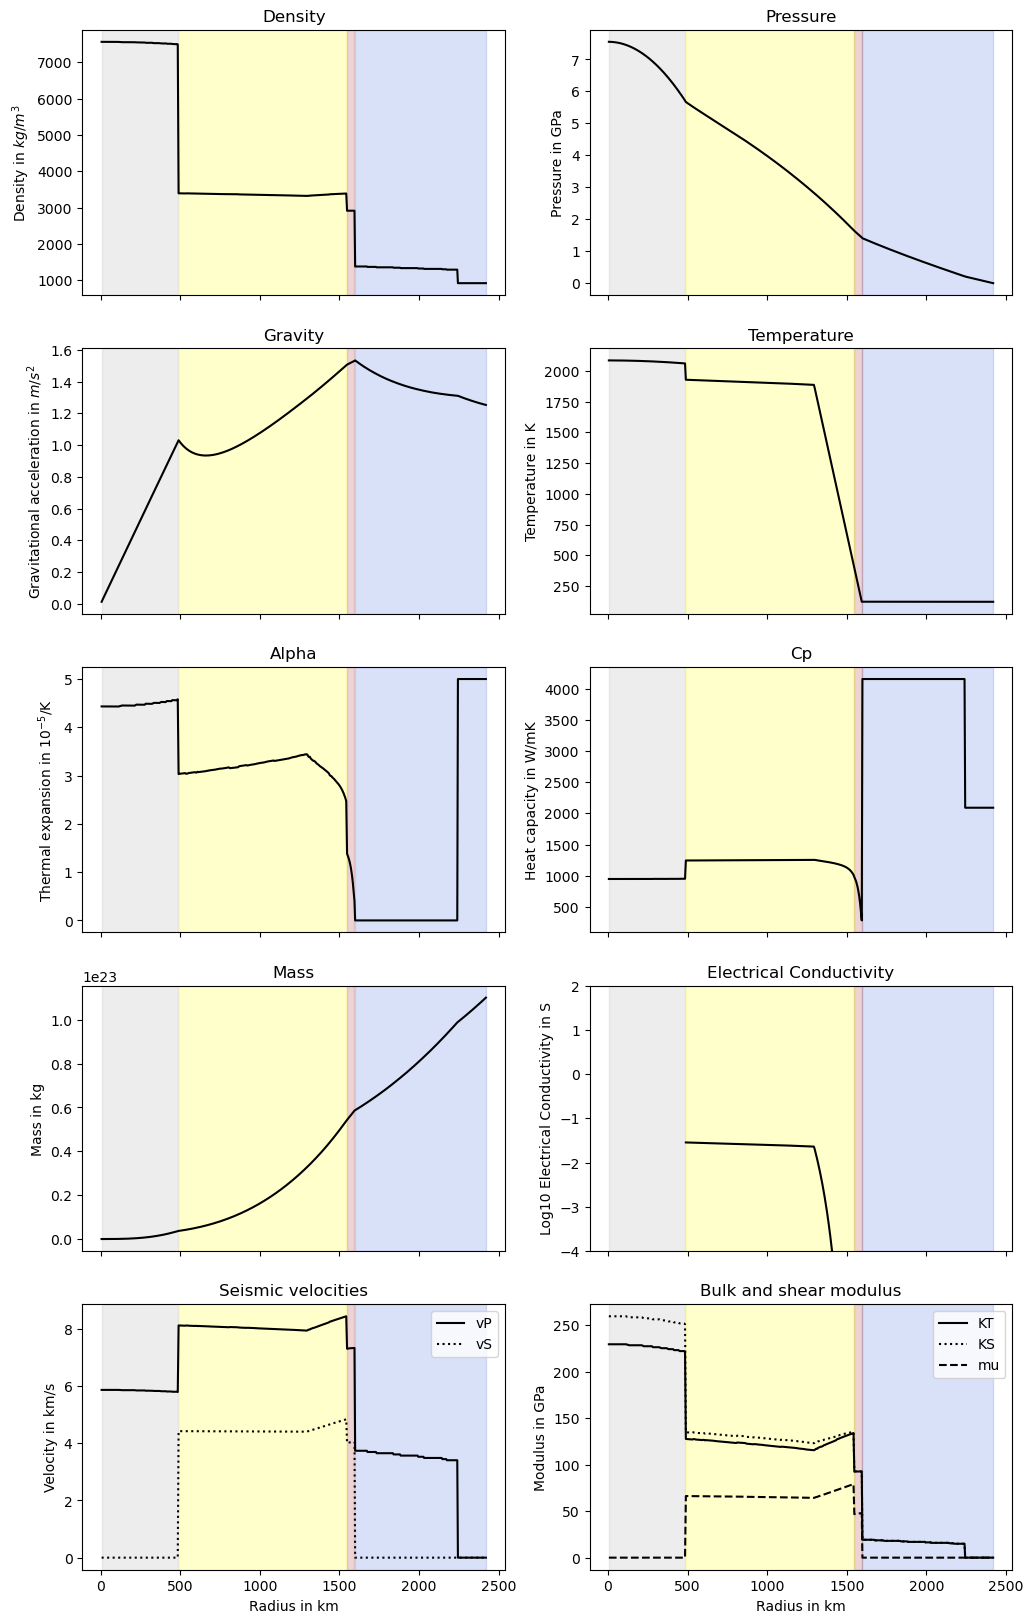

In [44]:
# Para  calisto
xelem_callisto = np.array([0.0, 0.0, 0.20, 0.0])
# Callisto não possui um valor conhecido de S, por isso utilizei o padrão para a terra e para o modelo ROWs.
if __name__ == "__main__":
    
    mass_obs = 0.0183
    radius_obs = 0.38
    temp_obs=temp_pla2(T_sol, r_s, 5.2)
    P_p=0
    xelem=xelem_callisto
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, xelem, -1,
        fe_range=(10, 90, 5), h2o_range=(0, 90, 10)) 
    
    
    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, xelem, -1,delta_Fe=0.3*best_Fe, delta_H2O=0.3*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p, xelem)

outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

D = Rc - Ric

if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    print(D/(radius_obs*R_t*1000), rho_core_mean)
else:
    print("The planet does not have a liquid outer core")
    print(D/(radius_obs*R_t*1000))



visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

In [21]:
xelem_callisto = np.array([0.0, 0.0, 0.20, 0.0])
mass_obs = 0.0183
radius_obs = 0.38
temp_obs=temp_pla2(T_sol, r_s, 5.2)
P_p=0
xelem=xelem_callisto

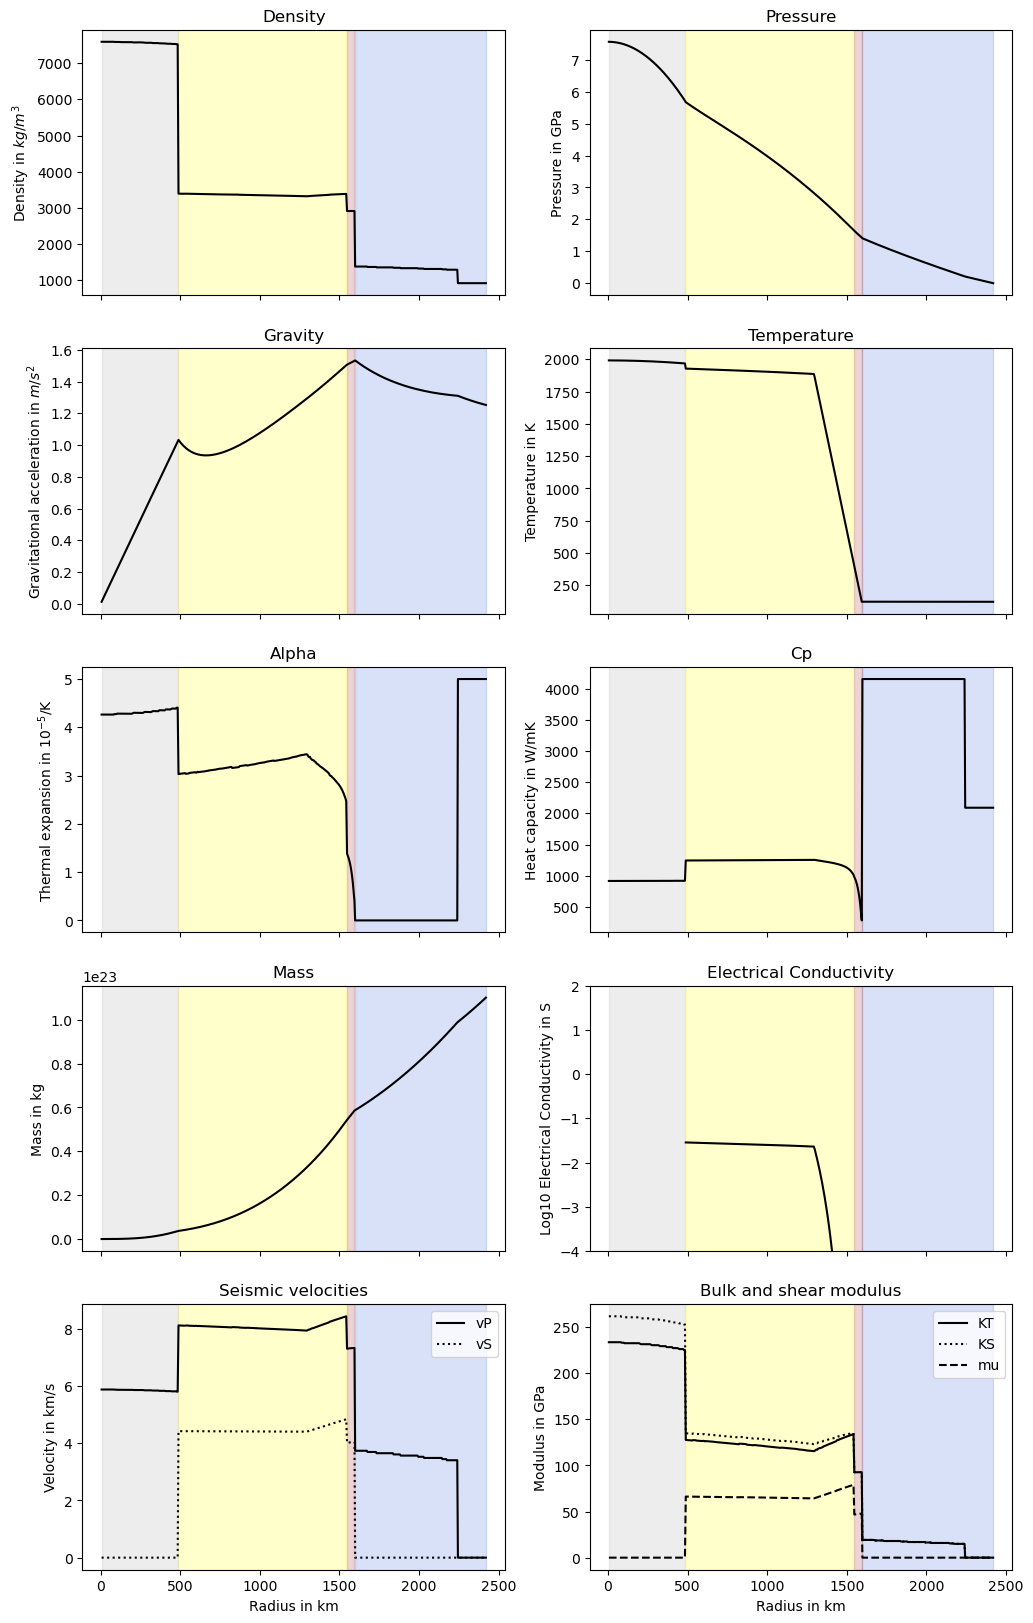

In [22]:
name='calisto'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 7.0, 47.0, temp_obs, P_p, xelem, -0.3)

outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

D = Rc - Ric

if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")



visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)



STEP 1: Coarse search
Testing 144 combinations.
[1/144] Fe=10, H2O=0 -> R=0.673 R_E, M=0.2107 M_E, Combined relative error=1.3545
[2/144] Fe=10, H2O=10 -> R=0.711 R_E, M=0.2114 M_E, Combined relative error=1.4862
[3/144] Fe=10, H2O=20 -> R=0.736 R_E, M=0.2114 M_E, Combined relative error=1.5728
[4/144] Fe=10, H2O=30 -> R=0.758 R_E, M=0.2114 M_E, Combined relative error=1.6508
[5/144] Fe=10, H2O=40 -> R=0.778 R_E, M=0.2114 M_E, Combined relative error=1.7212
[6/144] Fe=10, H2O=50 -> R=0.797 R_E, M=0.2114 M_E, Combined relative error=1.7878
[7/144] Fe=10, H2O=60 -> R=0.815 R_E, M=0.2114 M_E, Combined relative error=1.8482
[8/144] Fe=10, H2O=70 -> R=0.832 R_E, M=0.2113 M_E, Combined relative error=1.9105
[9/144] Fe=10, H2O=80 -> R=0.850 R_E, M=0.2112 M_E, Combined relative error=1.9703
[10/144] Fe=15, H2O=0 -> R=0.668 R_E, M=0.2108 M_E, Combined relative error=1.3343
[11/144] Fe=15, H2O=10 -> R=0.705 R_E, M=0.2115 M_E, Combined relative error=1.4662
[12/144] Fe=15, H2O=20 -> R=0.730 R_E, 

C:\Users\vitor\AppData\Local\Temp\ipykernel_24668\213928631.py:73: RuntimeWarning: invalid value encountered in scalar power
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius


[55/144] Fe=40, H2O=0 -> R=0.637 R_E, M=0.2111 M_E, Combined relative error=1.2265
[56/144] Fe=40, H2O=10 -> R=0.676 R_E, M=0.2116 M_E, Combined relative error=1.3642
[57/144] Fe=40, H2O=20 -> R=0.703 R_E, M=0.2117 M_E, Combined relative error=1.4566
[58/144] Fe=40, H2O=30 -> R=0.726 R_E, M=0.2117 M_E, Combined relative error=1.5368
[59/144] Fe=40, H2O=40 -> R=0.746 R_E, M=0.2117 M_E, Combined relative error=1.6073
[60/144] Fe=40, H2O=50 -> R=0.766 R_E, M=0.2117 M_E, Combined relative error=1.6772
[61/144] Fe=40, H2O=60 -> R=0.782 R_E, M=0.2116 M_E, Combined relative error=1.7329
[62/144] Fe=40, H2O=70 -> R=0.814 R_E, M=0.1922 M_E, Combined relative error=1.8467
[63/144] Fe=40, H2O=80 -> ERRO: cannot convert float NaN to integer
[64/144] Fe=45, H2O=0 -> R=0.630 R_E, M=0.2111 M_E, Combined relative error=1.2041
[65/144] Fe=45, H2O=10 -> R=0.670 R_E, M=0.2117 M_E, Combined relative error=1.3426
[66/144] Fe=45, H2O=20 -> R=0.697 R_E, M=0.2117 M_E, Combined relative error=1.4354
[67/144] F

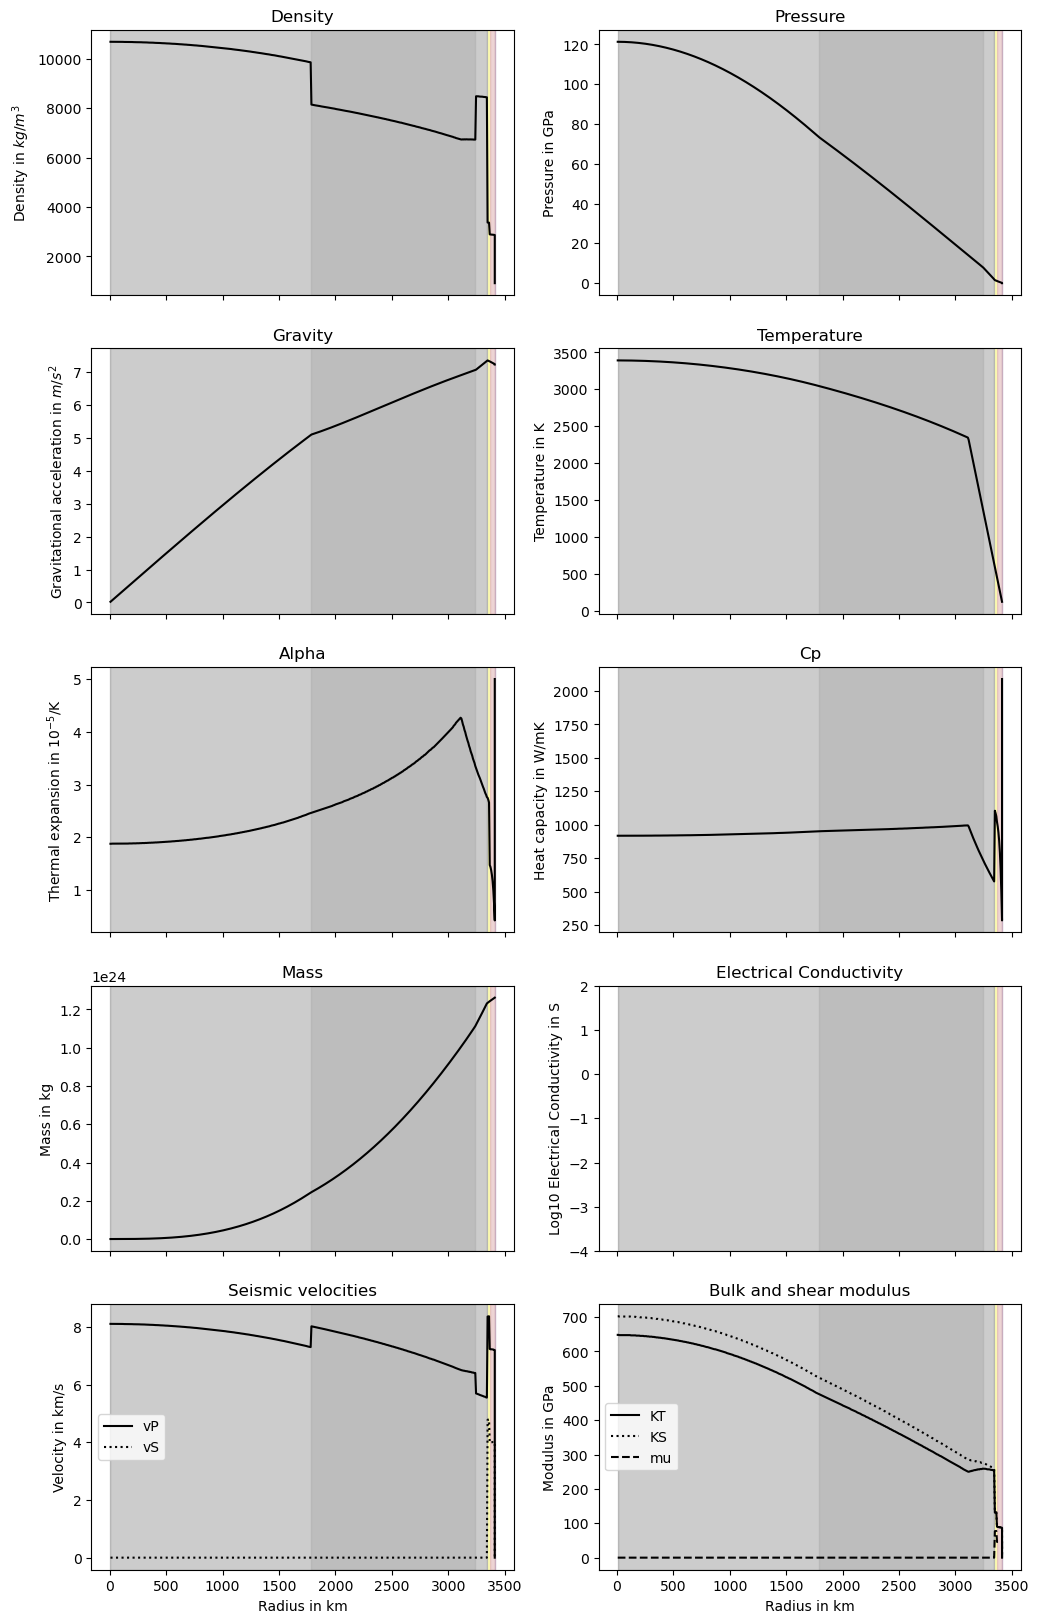

In [47]:
# Para  IO
xelem_io = np.array([0.0, 0.0, 0.35, 0.0])
# Referencia para S: SOHL, F. et al. Implications from Galileo observations on the interior structure and chemistry of the Galilean satellites. Icarus, v. 157, n. 1, p. 104-119, 2002.
if __name__ == "__main__":
    
    mass_obs = 0.21
    radius_obs = 0.286
    temp_obs=temp_pla2(T_sol, r_s, 5.2)
    P_p=0
    xelem=xelem_io
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, xelem, -1,
        fe_range=(10, 90, 5), h2o_range=(0, 90, 10)) 
    
    
    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, xelem,delta_Fe=0.3*best_Fe, delta_H2O=0.3*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p, xelem)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]] 
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

D = Rc - Ric

if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    print(D/(radius_obs*R_t*1000), rho_core_mean)
else:
    print("The planet does not have a liquid outer core")
    print(D/(radius_obs*R_t*1000))



visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

In [23]:
xelem_io = np.array([0.0, 0.0, 0.35, 0.0])
mass_obs = 0.21
radius_obs = 0.286
temp_obs=temp_pla2(T_sol, r_s, 5.2)
P_p=500
xelem=xelem_io

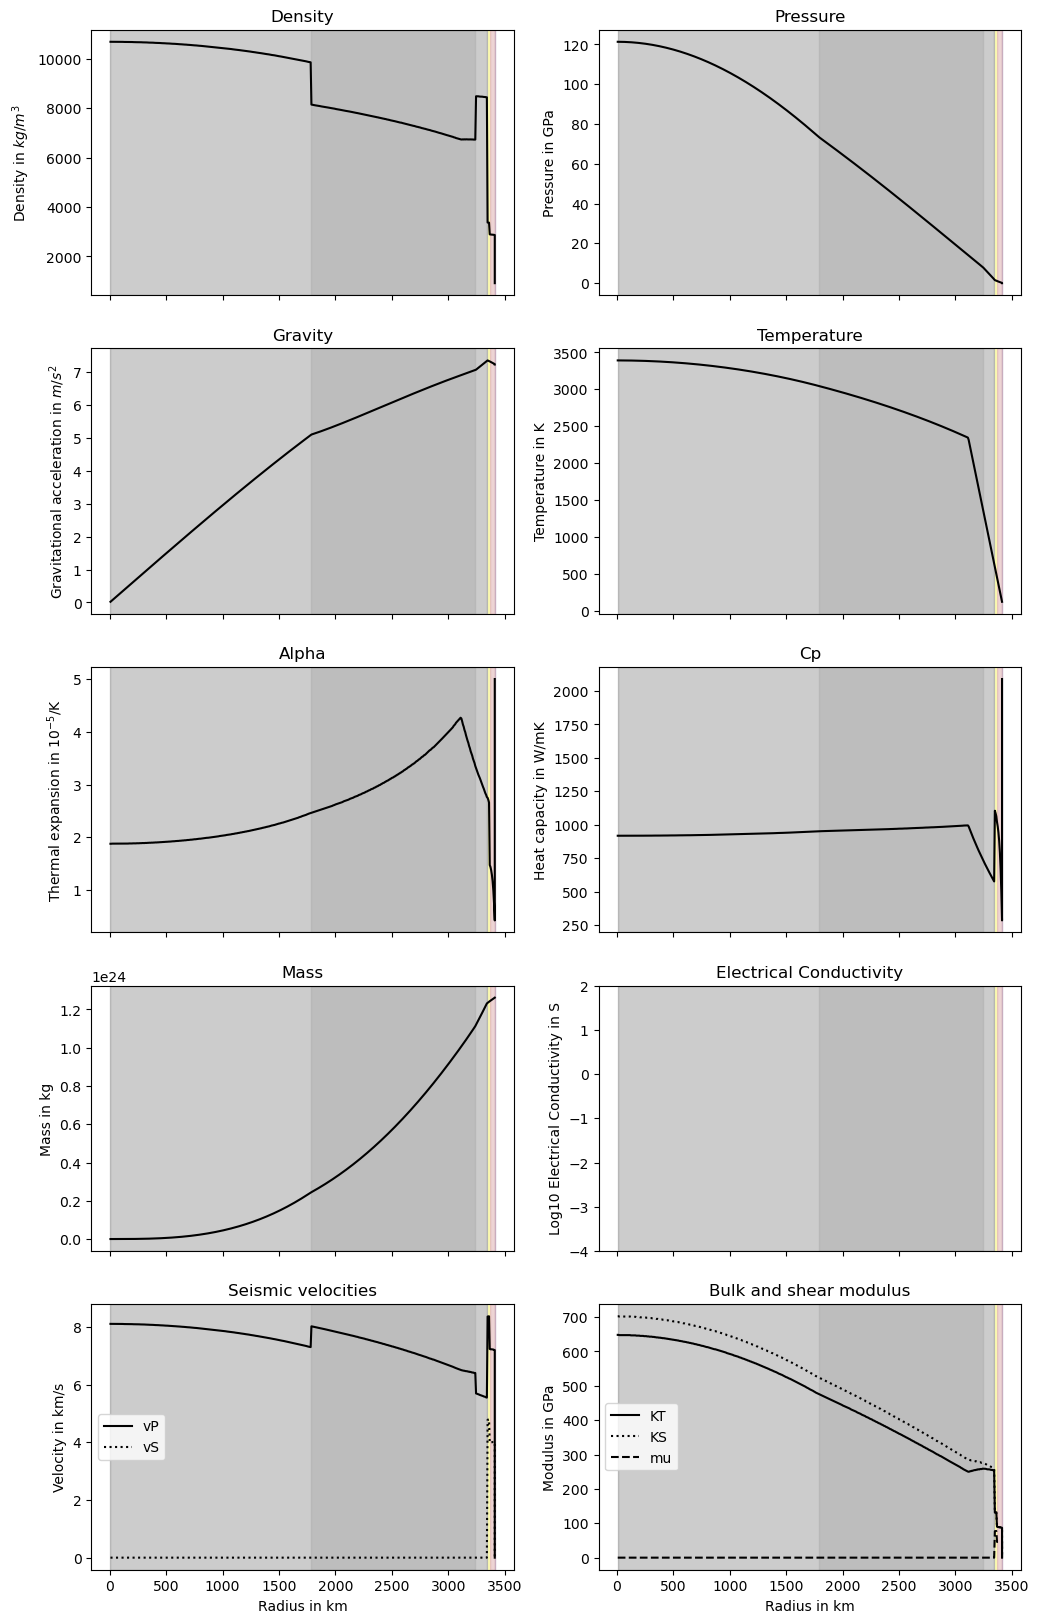

In [24]:
name='Io'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 97.75, 0.05, temp_obs, P_p, xelem)

outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

D = Rc - Ric

if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")

visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

STEP 1: Coarse search
Testing 144 combinations.
[1/144] Fe=10, H2O=0 -> R=0.345 R_E, M=0.0251 M_E, Combined relative error=0.1656
[2/144] Fe=10, H2O=10 -> R=0.367 R_E, M=0.0252 M_E, Combined relative error=0.1119
[3/144] Fe=10, H2O=20 -> R=0.382 R_E, M=0.0252 M_E, Combined relative error=0.0753
[4/144] Fe=10, H2O=30 -> R=0.396 R_E, M=0.0252 M_E, Combined relative error=0.0419
[5/144] Fe=10, H2O=40 -> R=0.409 R_E, M=0.0252 M_E, Combined relative error=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 40.0000 wt%
Combined relative error mínimo = 0.0132
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=10.0000, H2O=40.0000
Range Fe: 7.0000 to 13.0000 (step=0.5000)
Range H2O: 34.0000 to 46.0000 (step=0.6000)
Total number of combinations: 13 × 22 = 286
Testing 286 combinations.
[1/286] Fe=7.0, H2O=34.0 -> R=0.403 R_E, M=0.0252 M_E, Combined relative error=0.0254
[2/286] Fe=7.0, H2O=34.6 -> R=0.404 R_E, M=0.0252 M_E,

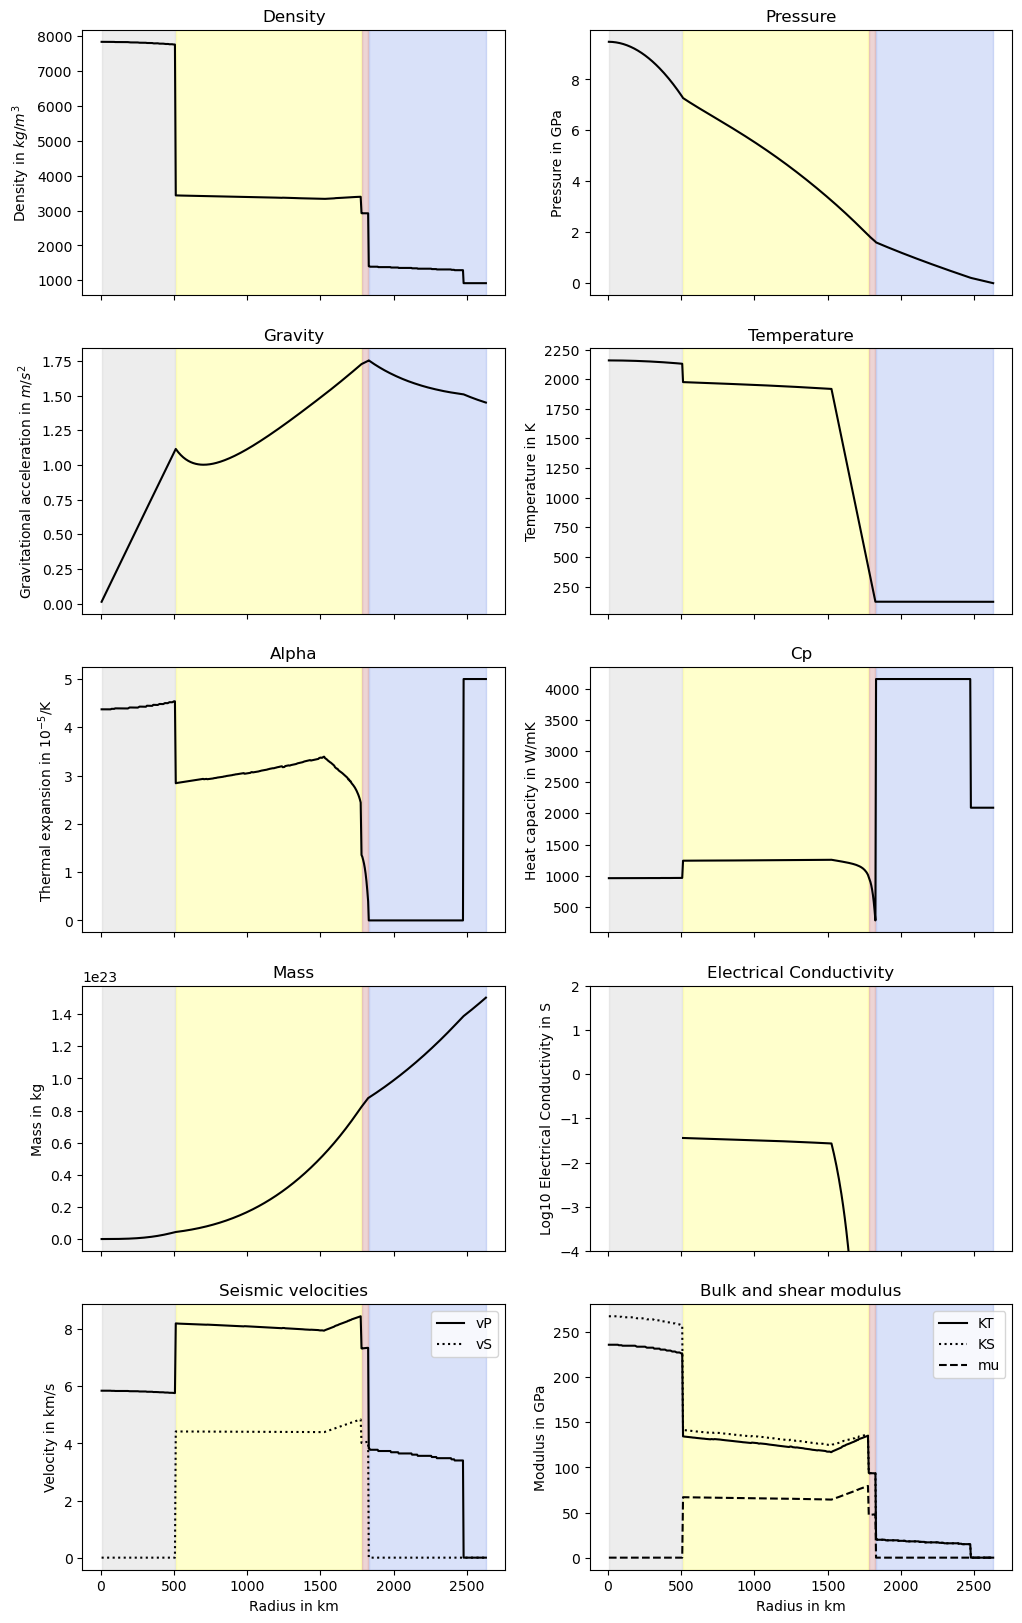

In [50]:
# Para  Ganimedes
xelem_ganymede = np.array([0.0, 0.0, 0.16, 0.0])
# Referencia para S: HAUCK, Steven A.; AURNOU, Jonathan M.; DOMBARD, Andrew J. Sulfur's impact on core evolution and magnetic field generation on Ganymede. Journal of Geophysical Research: Planets, v. 111, n. E9, 2006.
if __name__ == "__main__":
    mass_obs = 0.025
    radius_obs = 0.413
    temp_obs=temp_pla2(T_sol, r_s, 5.2)
    P_p=0
    xelem=xelem_ganymede
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, xelem, -1,
        fe_range=(10, 90, 5), h2o_range=(0, 90, 10)) 
    
    
    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, xelem, -1,delta_Fe=0.3*best_Fe, delta_H2O=0.3*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p, xelem)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

D = Rc - Ric

if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    print(D/(radius_obs*R_t*1000), rho_core_mean)
else:
    print("The planet does not have a liquid outer core")
    print(D/(radius_obs*R_t*1000))



visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

In [25]:
xelem_ganymede = np.array([0.0, 0.0, 0.16, 0.0])
mass_obs = 0.025
radius_obs = 0.413
temp_obs=temp_pla2(T_sol, r_s, 5.2)
P_p=0
xelem=xelem_ganymede

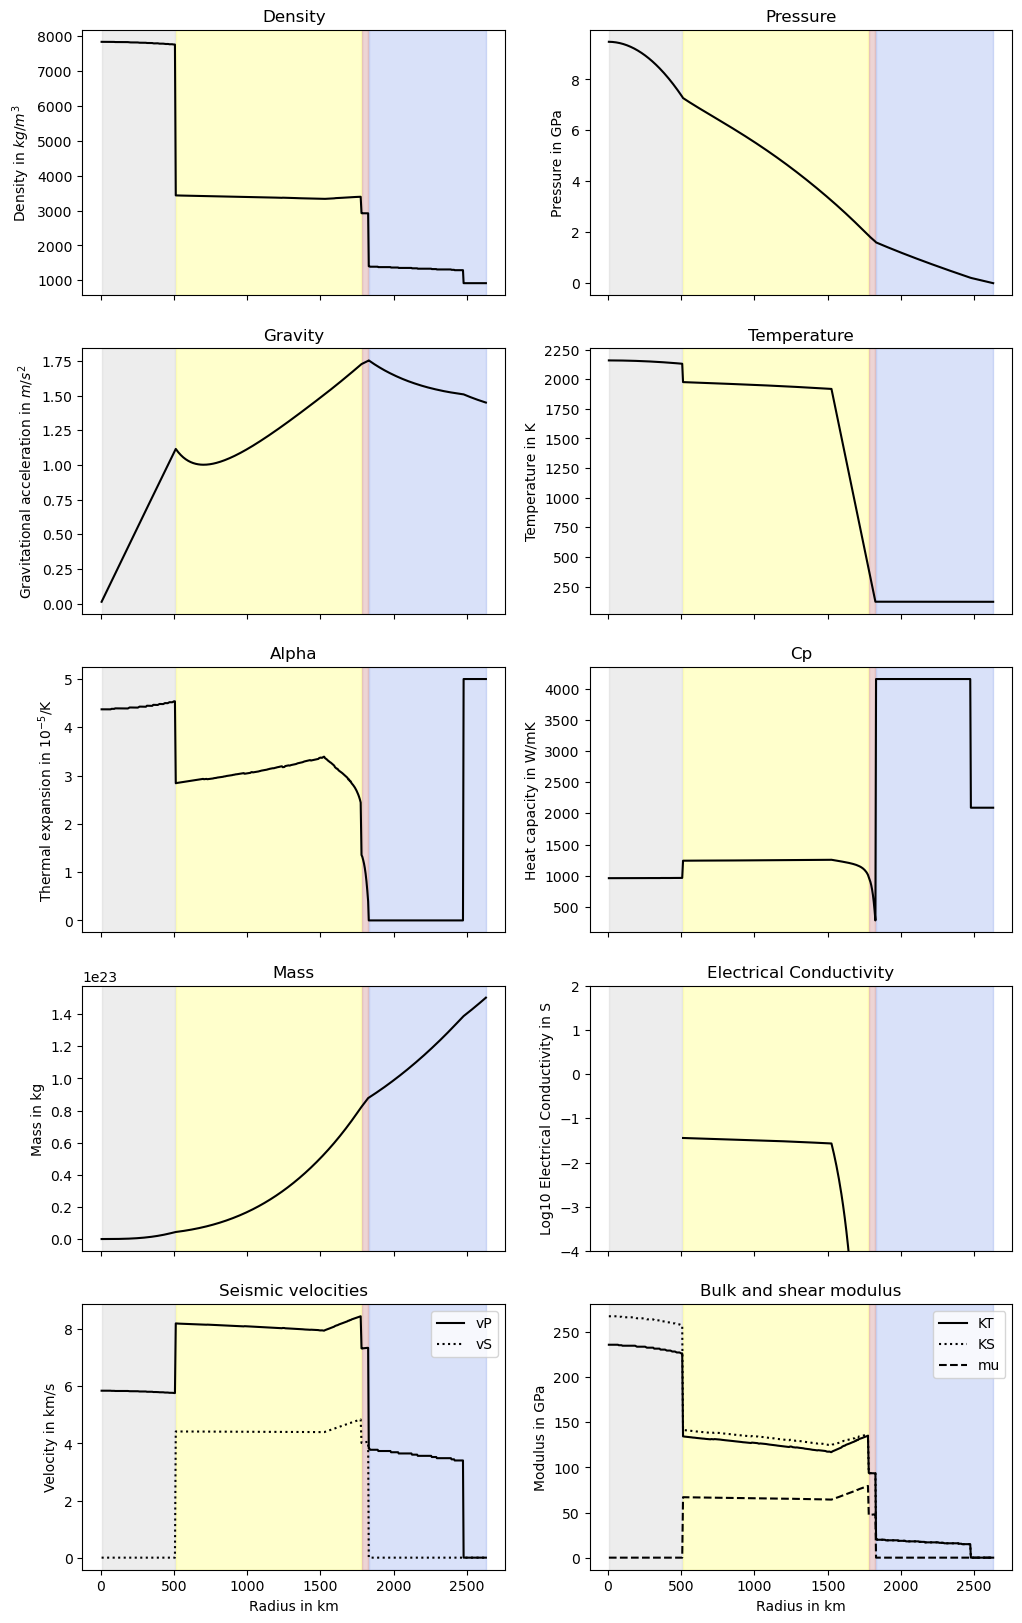

In [26]:
name='ganimedes'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 7.0, 41.80, temp_obs, P_p, xelem_ganymede)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]] 
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0


D = Rc - Ric


if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")



visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)



In [27]:
resultados

{'name': ['Terra',
  'Venus',
  'mercury',
  'mars',
  'moon',
  'europa',
  'calisto',
  'Io',
  'ganimedes'],
 'rho_core_mean': [np.float64(11145.477628867115),
  nan,
  np.float64(9109.775025868912),
  np.float64(8161.178387001204),
  np.float64(8117.56239953052),
  np.float64(7638.200953526635),
  np.float64(7566.343407607508),
  np.float64(7450.033265483667),
  np.float64(7801.655849204106)],
 'cp_core_mean': [np.float64(1119.0100630509176),
  nan,
  np.float64(908.9800559879462),
  np.float64(922.8363308105369),
  np.float64(894.6253784878495),
  np.float64(889.5712552062732),
  np.float64(916.950090500045),
  np.float64(960.1418961943377),
  np.float64(961.8192537695483)],
 'T_cmb': [np.float64(4896.624938425413),
  nan,
  np.float64(2076.5178777519104),
  np.float64(2301.2567163498247),
  np.float64(1891.745507971971),
  np.float64(1852.153405184782),
  np.float64(1968.0837082452133),
  np.float64(1402.0929737617594),
  np.float64(2129.8602674722515)],
 'P_cmb': [np.float64(135

In [28]:
import pandas as pd

In [29]:
df_resultados=pd.DataFrame(resultados)

In [30]:
df_resultados

,name,rho_core_mean,cp_core_mean,T_cmb,P_cmb,Ric,Rc,D
0,Terra,11145.477629,1119.010063,4896.624938,1.354078e+11,1.410773e+06,3.520340e+06,2.109567e+06
1,Venus,NaN,NaN,NaN,NaN,0.000000e+00,3.012636e+06,3.012636e+06
2,mercury,9109.775026,908.980056,2076.517878,9.196088e+09,8.170758e+05,1.756468e+06,9.393925e+05
3,mars,8161.178387,922.836331,2301.256716,2.237380e+10,0.000000e+00,1.563256e+06,1.563256e+06
4,moon,8117.562400,894.625378,1891.745508,5.049640e+09,0.000000e+00,5.044434e+05,5.044434e+05
5,europa,7638.200954,889.571255,1852.153405,3.670332e+09,0.000000e+00,5.478610e+05,5.478610e+05
6,calisto,7566.343408,916.950091,1968.083708,5.715624e+09,0.000000e+00,4.837163e+05,4.837163e+05
7,Io,7450.033265,960.141896,1402.092974,8.126467e+09,1.787854e+06,3.240058e+06,1.452203e+06
8,ganimedes,7801.655849,961.819254,2129.860267,7.321830e+09,0.000000e+00,5.068215e+05,5.068215e+05


In [31]:
df=pd.read_csv('dados fe artigo - Página1.csv')

In [32]:
def encontrar_x(df: pd.DataFrame, temperatura: float, pressao: float):
    """
    Retorna o Volume do ponto (T, P) mais próximo.
    """

    # Verifica se a entrada é NaN
    if pd.isna(temperatura) or pd.isna(pressao):
        return np.nan  # ou np.nan, ou lançar erro

    t_min, t_max = df['Temperature (K)'].min(), df['Temperature (K)'].max()
    p_min, p_max = df['Pexp (GPa)b'].min(), df['Pexp (GPa)b'].max()

    def norm(col, minimo, maximo):
        if maximo == minimo:
            return col * 0.0
        return (col - minimo) / (maximo - minimo)

    t_norm_col = norm(df['Temperature (K)'], t_min, t_max)
    p_norm_col = norm(df['Pexp (GPa)b'], p_min, p_max)

    t_norm = norm(pd.Series([temperatura]), t_min, t_max).iloc[0]
    p_norm = norm(pd.Series([pressao]), p_min, p_max).iloc[0]

    distancias = ((t_norm_col - t_norm)**2 + (p_norm_col - p_norm)**2)**0.5

    idx_mais_proximo = distancias.idxmin()

    return df.loc[idx_mais_proximo, 'Volume (cm3/mol)']

In [33]:
resultados['V']=[]

In [34]:
for i in np.arange(len(resultados['name'])):
    resultados['V'].append(encontrar_x(df, resultados['T_cmb'][i],resultados['P_cmb'][i]/(10**9)))

In [35]:
df_resultados=pd.DataFrame(resultados)

In [36]:
df_resultados

,name,rho_core_mean,cp_core_mean,T_cmb,P_cmb,Ric,Rc,D,V
0,Terra,11145.477629,1119.010063,4896.624938,1.354078e+11,1.410773e+06,3.520340e+06,2.109567e+06,5.294
1,Venus,NaN,NaN,NaN,NaN,0.000000e+00,3.012636e+06,3.012636e+06,NaN
2,mercury,9109.775026,908.980056,2076.517878,9.196088e+09,8.170758e+05,1.756468e+06,9.393925e+05,8.132
3,mars,8161.178387,922.836331,2301.256716,2.237380e+10,0.000000e+00,1.563256e+06,1.563256e+06,7.473
4,moon,8117.562400,894.625378,1891.745508,5.049640e+09,0.000000e+00,5.044434e+05,5.044434e+05,8.132
5,europa,7638.200954,889.571255,1852.153405,3.670332e+09,0.000000e+00,5.478610e+05,5.478610e+05,8.132
6,calisto,7566.343408,916.950091,1968.083708,5.715624e+09,0.000000e+00,4.837163e+05,4.837163e+05,8.132
7,Io,7450.033265,960.141896,1402.092974,8.126467e+09,1.787854e+06,3.240058e+06,1.452203e+06,8.132
8,ganimedes,7801.655849,961.819254,2129.860267,7.321830e+09,0.000000e+00,5.068215e+05,5.068215e+05,8.132


In [37]:
def sigma(V, T):
    if pd.isna(T) or pd.isna(V):
        return None  # ou np.nan, ou lançar erro
    rho_bg=rho_0*(V/V_0)**a+rho_1*(V/V_0)**b*(T/T_0)
    rho_sat=c*(V/V_0)**(1/3)
    rho_el=d*(T_0/T)
    sigma_=(1/rho_bg)+(1/rho_sat)+(1/rho_el)
    if pd.isna(sigma_):
        return sigma_  # ou np.nan, ou lançar erro
    sigma_=sigma_*10**8
    return sigma_

In [38]:
resultados['sigma']=[]

In [39]:
resultados.keys()

dict_keys(['name', 'rho_core_mean', 'cp_core_mean', 'T_cmb', 'P_cmb', 'Ric', 'Rc', 'D', 'V', 'sigma'])

In [40]:
a=0.792
b=1.479
c=747.2
d=1405
rho_0=75.10
rho_1=21.48
T_0=3000
V_0=7.121

In [41]:
sigma(5.294, 4898.575930)

1483369.957598727

In [42]:
for i in np.arange(len(resultados['name'])):
    resultados['sigma'].append(sigma(resultados['V'][i], resultados['T_cmb'][i]))

In [43]:
df_resultados=pd.DataFrame(resultados)

In [44]:
df_resultados

,name,rho_core_mean,cp_core_mean,T_cmb,P_cmb,Ric,Rc,D,V,sigma
0,Terra,11145.477629,1119.010063,4896.624938,1.354078e+11,1.410773e+06,3.520340e+06,2.109567e+06,5.294,1.483458e+06
1,Venus,NaN,NaN,NaN,NaN,0.000000e+00,3.012636e+06,3.012636e+06,NaN,NaN
2,mercury,9109.775026,908.980056,2076.517878,9.196088e+09,8.170758e+05,1.756468e+06,9.393925e+05,8.132,1.162333e+06
3,mars,8161.178387,922.836331,2301.256716,2.237380e+10,0.000000e+00,1.563256e+06,1.563256e+06,7.473,1.230997e+06
4,moon,8117.562400,894.625378,1891.745508,5.049640e+09,0.000000e+00,5.044434e+05,5.044434e+05,8.132,1.173822e+06
5,europa,7638.200954,889.571255,1852.153405,3.670332e+09,0.000000e+00,5.478610e+05,5.478610e+05,8.132,1.176351e+06
6,calisto,7566.343408,916.950091,1968.083708,5.715624e+09,0.000000e+00,4.837163e+05,4.837163e+05,8.132,1.169014e+06
7,Io,7450.033265,960.141896,1402.092974,8.126467e+09,1.787854e+06,3.240058e+06,1.452203e+06,8.132,1.206854e+06
8,ganimedes,7801.655849,961.819254,2129.860267,7.321830e+09,0.000000e+00,5.068215e+05,5.068215e+05,8.132,1.159109e+06


In [45]:
df_resultados.to_excel('sigma_sistema_solar.xlsx')

In [46]:
df_resultados.to_csv('sigma_sistema_solar.csv')